# The direction words and the comparison, given to the seed

`05` ended with the label seed at test reward 0.916 and decisions 0.908, PPO adding nothing to it, and two things
left in its answers. On `holdout_shift` the seed wrote the comparison operator the wrong way round on
98 of 655 items: all 71 that limit salt rejection and all 27 that limit
system recovery, 0 of the rest and 0 on test. Those two limits are stated by the two sentences holdout_shift uses
and train never does ("Rejection must not fall under 99 %" became `<= 99`); every other limit's unseen
sentence was read right. On test, 26 of the seed's 37 wrong verdicts compared or copied a right number wrongly.

This notebook changes two things in the task, and seeds PPO another way. **One more sentence per limit in train** (other words
for "at least" and "at most"; dev and test unchanged, holdout_shift's sentences still unseen).
**A tool, `check_limits`**, called once per question with every limit as the user stated it (number and unit; the
tool converts) and every candidate's limited values, whose response is the comparison lines themselves
(`A: permeate.flow_kg_s 0.9193 breaks >= 1.11111; ... -> fail`), so every comparison line is a copy of a tool
response, as the limit became in `05`. It opens with the diagnostic that justifies the first: the seed of
`05`, on holdout_shift with that one sentence restated the way train states it.

**The sentence is the cause.** With every limit restated by 05's first train sentence, 05's seed writes
0 of the holdout_shift operators wrong (before: 98) and decides 105 of 120 questions right
(before: 71); with every limit on test restated by holdout_shift's unseen sentence it writes
231 of 1414 operators wrong (before: 0) and decides 172 of 240 right (before: 218).

**Held out, greedy, answers stopped at their closing brace:**

| policy | test reward | decision right | whole answer right | proving simulations |
| --- | --- | --- | --- | --- |
| 05: the label seed | 0.916 | 0.908 | 0.817 | 0.983 |
| 05: PPO, best of 244 steps | 0.920 | 0.908 | 0.846 | 0.988 |
| 06: 1200 reference episodes, one epoch (the next dose) | 0.925 | 0.917 | 0.879 | 0.942 |
| 06: the seed, 600 reference episodes, one epoch | 0.816 | 0.796 | 0.775 | 0.775 |

| policy | holdout_shift reward | decision right | whole answer right | proving simulations |
| --- | --- | --- | --- | --- |
| 05: the label seed | 0.699 | 0.592 | 0.450 | 0.892 |
| 05: PPO, best of 244 steps | 0.739 | 0.650 | 0.517 | 0.900 |
| 06: 1200 reference episodes, one epoch (the next dose) | 0.880 | 0.867 | 0.850 | 0.867 |
| 06: the seed, 600 reference episodes, one epoch | 0.802 | 0.767 | 0.717 | 0.775 |

06's seed against 05's on holdout_shift: right only under 06 30, only under 05 9 (p = 1.1e-03).

- **Both tools are served here, not on the deployed server.** `convert_units` and `check_limits` are declared to
  the model like the two simulators and run by the same host; the MCP server on temur has neither, so a policy
  trained here needs them added there before it can be deployed.
- **Nothing changes for dev, test or holdout_shift.** Their questions are 05's byte for byte; only train is drawn
  again, from the wider sentence bank. The decomposition and the held-out protocol are 05's.
- **The seed is the smallest SFT dose that is alive, not 05's label seed.** Plain SFT on the
  first *N* reference episodes of one shuffle, one epoch, *N* doubling from 10; the first dose at which every behaviour
  the task needs, and every answer class, has been sampled right at least once on dev goes to PPO. No quality bar:
  PPO's job is the activation, and a label PPO cannot activate is still dead -- it gets a little more SFT, the next dose, not a gate.
  Two runs with the tool gate on, from 300 and 600 episodes, were stopped by it at steps 63 and 45, their best evaluations at step 0. With the tool gate off, at 05's lambda 0.95, the run from the seed ended at step 121 (answer collapse), its best evaluation step 0; its sampled episodes show it learning to skip the unit conversion: on the questions with a unit to convert, convert calls per episode 2.44 in the warm-up to 1.11 over the last 25 steps, the first simulate call erroring 0.50 to 0.70, answered 0.67 to 0.30. With lambda 1, the one variable changed, the run ended at step 200 (converged), its best evaluation step 0 at 0.879 against 0.879 at the start; on the questions with a unit to convert its sampled episodes went the other way, convert calls per episode 2.69 in the warm-up to 3.05 over the last 25 steps, 0.15 of them converting a value already in the tool's units to itself; its evaluations after the warm-up fell to 0.555 at step 50 (0.35 of the episodes cut at the token budget) and then stayed between 0.783 and 0.820; none of the three criteria written before it ran is met. With the turn as the unit of credit (lambda 0.95 per turn), the third run from the seed ended at step 150 (critic gate), its best evaluation step 0 at 0.879 against 0.879 at the start; its sampled episodes improved for the first 50 actor steps (reward 0.722 in the warm-up to 0.804 over steps 50-74, whole answers right 0.63 to 0.70) and then the policy ran away (KL to the seed 3.16 per token over the last 25 steps, no call at all); none of the three criteria is met. With the turn as the unit and the actor step a fifth (lr 2e-6), the fourth run from the seed ended at step 200 (converged), its best evaluation step 0 at 0.879 against 0.879 at the start; its sampled episodes improved (reward 0.722 in the warm-up to 0.810 over steps 150-174, whole answers right 0.63 to 0.73) and held (reward 0.783 over the last 25 steps, KL to the seed 0.0023 per token); none of the three criteria is met. Sampled twice at T=1 on all 240 dev questions, its last checkpoint scores 0.830 against the seed's 0.702 (paired difference +0.128, 95% interval +0.095 to +0.161): PPO moved what the policy samples, not its greedy path. The next dose, 1200 episodes, at lambda 0.95: the run ended at step 200 (converged), its best evaluation step 0 at 0.947 against 0.947 at the start; on the questions with a unit to convert, the first simulate call erred 0.00 in the warm-up and 0.22 over the last 25 steps, 0.13 of those episodes passing a number the question states in another unit to the simulator unconverted (0.06 in the warm-up); none of the lambda-1 run's three criteria is met.
- **The policy's token budget is 3,072** (05: 2,048): the check call restates every limit and limited value once,
  and the reference trajectories run to 2,148 policy tokens (05's to 1,796); the budget has to hold the reference.

In [1]:
import collections, importlib.util, json, math, re, statistics as st, sys
from pathlib import Path

HERE = Path.cwd() if (Path.cwd() / "06_direction_and_compare.py").exists() else Path("experiments/notebooks/smoke_test35")
# This notebook's own module (05's, copied and changed as the header says); loaded by path because the
# file name starts with a digit. Scoring, the tools and the checks are pure Python: nothing below needs
# WaterTAP or a GPU.
spec = importlib.util.spec_from_file_location("nw06", HERE / "06_direction_and_compare.py")
nw = importlib.util.module_from_spec(spec)
sys.modules["nw06"] = nw
spec.loader.exec_module(nw)
RUNS, RUNS05 = nw.RUNS, HERE / "05_units_and_scans_runs"
SEED06, CKPT06 = "label-seed-n600", "epoch1"   # the seed PPO starts from
BESTS = []   # (label, run) of each PPO run whose best evaluation is a checkpoint of its own, held out
splits = {s: nw.load_split(s) for s in nw.SPLITS}
checks = json.loads((HERE / "06_direction_and_compare_checks.json").read_text())


def rows_of(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines()]


def cases_of(split, data_dir=None):
    d = data_dir or nw.DATA
    return {c["id"]: c for c in map(json.loads, (d / f"{split}.jsonl").read_text().splitlines())}


print({s: len(c) for s, c in splits.items()}, "| tools:", ", ".join(nw.ALL_TOOLS))

{'train': 1200, 'dev': 240, 'test': 240, 'holdout_shift': 120} | tools: simulate_ro, simulate_swro_system, convert_units, check_limits


## What 05's seed got wrong, and where

05's item-by-item account of a policy's answers is reused as it is: every comparison line has the form
`field value meets|breaks op limit`, and each item's limit is checked against the scenario's threshold,
its operator against the limit's direction, its value against the simulation, and its verdict against
the truth. One count is added: the operators written wrong, per limited field. On test 05's seed wrote
none wrong. On holdout_shift it wrote every one wrong for two fields and none for the other seven.

In [2]:
ITEM = re.compile(r"(?P<metric>[\w.]+) (?P<value>-?[\d.]+(?:e-?\d+)?) (?P<verdict>meets|breaks) (?P<op><=|>=) (?P<limit>-?[\d.]+(?:e-?\d+)?)")
LINE = re.compile(r"^(?P<label>[^:]+):\s*(?P<body>.*?)\s*->\s*(?P<verdict>pass|fail)\s*$")


def rel(a, b):
    return abs(a - b) / max(abs(b), 1e-9)


def decompose(path, cases):
    """Item-by-item account of a probe's episodes: limits, operators, comparison logic, proving
    simulations by unit level, scan aggregation, wrong decisions by source."""
    c_ = collections.Counter()
    lvl = collections.defaultdict(collections.Counter)
    ops = collections.defaultdict(lambda: [0, 0])
    for ep in rows_of(path):
        case = cases[ep["id"]]
        L = lvl[case["level"]]
        L["n"] += 1
        L["evidence"] += bool(ep["score"]["evidence"])
        L["decision"] += bool(ep["score"]["decision_correct"])
        thr = {k["metric"]: k for k in case["constraints"]}
        pts = {p["label"]: p for p in case["points"]} if case["decision_kind"] != "passfail" else {"Result": case["points"][0]}
        text = ep["final_text"].split("{")[0]
        written = {}
        for ln in text.splitlines():
            m = LINE.match(ln.strip())
            if not m or m["label"].strip() not in pts:
                continue
            written[m["label"].strip()] = m["verdict"]
            p = pts[m["label"].strip()]
            for it in ITEM.finditer(m["body"]):
                k = thr.get(it["metric"])
                if k is None or it["metric"] not in p["metrics"]:
                    continue
                c_["items"] += 1
                ops[k["metric"]][1] += 1
                ops[k["metric"]][0] += it["op"] != k["op"]
                lim, v = float(it["limit"]), float(it["value"])
                tv, tl = p["metrics"][it["metric"]], k["threshold"]
                needs = rel(k["user_value"], tl) > 0.005
                if needs:
                    c_["limits needing conversion"] += 1
                    c_["  written right"] += rel(lim, tl) <= 0.005
                    c_["  the user's number copied"] += rel(lim, tl) > 0.005 and rel(lim, k["user_value"]) <= 0.005
                true_meets = (tv >= tl) if k["op"] == ">=" else (tv <= tl)
                if (it["verdict"] == "meets") == true_meets:
                    c_["verdict right"] += 1
                elif rel(lim, tl) > 0.005:
                    c_["verdict wrong: limit wrong"] += 1
                elif rel(v, tv) > 0.02:
                    c_["verdict wrong: value wrong"] += 1
                elif it["op"] != k["op"]:
                    c_["verdict wrong: operator wrong"] += 1
                else:
                    c_["verdict wrong: comparison"] += 1
        if case["decision_kind"] == "number" and ep["score"]["evidence"] and not ep["score"]["decision_correct"]:
            order = [p["label"] for p in case["points"]]
            passing = [l for l in order if written.get(l) == "pass"]
            want = (passing[0] if case["objective"] == "lowest" else passing[-1]) if passing else "none"
            obj = nw.extract_answer(ep["final_text"])[0] or {}
            d = obj.get("decision")
            said = "none" if nw._none_like(d) else str(d)
            wrong_verdict = any((written.get(l) == "pass") != all(
                (p["metrics"][k["metric"]] >= k["threshold"]) if k["op"] == ">=" else (p["metrics"][k["metric"]] <= k["threshold"])
                for k in case["constraints"]) for l, p in pts.items() if l in written)
            c_["scan wrong after right sims"] += 1
            c_["  a verdict wrong"] += wrong_verdict
            c_["  verdicts right, pick wrong"] += (not wrong_verdict) and said != want
            c_["  verdicts and pick right, decision differs"] += (not wrong_verdict) and said == want
        if not ep["score"]["decision_correct"]:
            c_["wrong decisions"] += 1
            if nw.extract_answer(ep["final_text"])[0] is None:
                c_["  no answer"] += 1
            elif not ep["score"]["evidence"]:
                c_["  proving simulation missing"] += 1
            else:
                c_["  after the right simulations"] += 1
    return c_, lvl, ops


def show(title, path, cases, operators=False):
    c_, lvl, ops = decompose(path, cases)
    print(f"== {title}")
    for k in ("items", "verdict right", "verdict wrong: limit wrong", "verdict wrong: value wrong",
              "verdict wrong: operator wrong", "verdict wrong: comparison", "limits needing conversion",
              "  written right", "  the user's number copied", "wrong decisions", "  no answer",
              "  proving simulation missing", "  after the right simulations", "scan wrong after right sims",
              "  a verdict wrong", "  verdicts right, pick wrong", "  verdicts and pick right, decision differs"):
        print(f"   {k:46} {c_.get(k, 0)}")
    for l in sorted(lvl):
        L = lvl[l]
        print(f"   unit level {l}: n {L['n']:3}, proving simulations {L['evidence'] / L['n']:.3f}, decisions {L['decision'] / L['n']:.3f}")
    if operators:
        print("   operators written wrong, per limited field:")
        for m, (w, n) in sorted(ops.items(), key=lambda kv: (-kv[1][0], kv[0])):
            print(f"      {m:40} {w:3}/{n}")
    return c_, lvl, ops


test05, hold05 = cases_of("test", nw.DATA_05), cases_of("holdout_shift", nw.DATA_05)
d05 = {}
for name, path, cs in (("05's seed, test", RUNS05 / "label-seed-pc2" / "epoch3" / "test-T0-stop.episodes.jsonl", test05),
                       ("05's seed, holdout_shift", RUNS05 / "label-seed-pc2" / "epoch3" / "holdout_shift-T0-stop.episodes.jsonl", hold05)):
    d05[name] = show(name, path, cs, operators=True)
    print()

== 05's seed, test
   items                                          1398
   verdict right                                  1361
   verdict wrong: limit wrong                     11
   verdict wrong: value wrong                     10
   verdict wrong: operator wrong                  0
   verdict wrong: comparison                      16
   limits needing conversion                      131
     written right                                117
     the user's number copied                     10
   wrong decisions                                22
     no answer                                    2
     proving simulation missing                   2
     after the right simulations                  18
   scan wrong after right sims                    11
     a verdict wrong                              10
     verdicts right, pick wrong                   1
     verdicts and pick right, decision differs    0
   unit level 0: n 104, proving simulations 1.000, decisions 0.971
   unit leve

## Is it the sentence?

Every limit's direction is fixed by what it limits: a permeate flow, a rejection or a recovery
target has a floor, a salinity, a flux, an energy or a cost has a ceiling. What varies is the
sentence that states it. In 05 (and 04) each limit had two or three sentences, drawn by train, dev
and test alike, and one more that only holdout_shift draws. For salt rejection and system recovery
the unseen sentences are "Rejection must not fall under {v}." and "We need plant recovery of {v} or
better.", and the seed read both as ceilings -- while "Downstream needs no less than {v} of product
water.", also unseen, it read right.

The probe below restates the limits and nothing else: 05's seed, under 05's own tool declarations,
on holdout_shift with every limit stated by 05's first train sentence, and on test with every limit
stated by holdout_shift's unseen sentence. The numbers, the units, the other sentences and the
answers stay. It is a diagnostic of the sentence, not a benchmark, and nothing is trained on it.

In [3]:
print("the sentences, per limit: 05's (train, dev, test) | holdout_shift's unseen one | 06's train-only ones\n")
for (metric, op), (shared, hold) in nw.CONSTRAINTS.items():
    print(f"{metric} {op}")
    for s in shared:
        print(f"   05      {s}")
    for s in hold:
        print(f"   holdout {s}")
    for s in nw.CONSTRAINTS_TRAIN_EXTRA[(metric, op)]:
        print(f"   06      {s}")

the sentences, per limit: 05's (train, dev, test) | holdout_shift's unseen one | 06's train-only ones

permeate.flow_kg_s >=
   05      We need at least {v} of permeate.
   05      Production can't drop below {v} of permeate.
   05      The permeate target is {v} minimum.
   holdout Downstream needs no less than {v} of product water.
   06      Permeate must not come in under {v}.
permeate.nacl_ppm <=
   05      Permeate NaCl has to stay at or below {v}.
   05      Product water must be under {v} NaCl.
   05      The permeate salinity limit is {v}.
   holdout Our quality cap on permeate NaCl is {v}.
   06      Permeate NaCl must not go over {v}.
performance.water_recovery_pct <=
   05      Recovery can't exceed {v}.
   05      We don't run recovery above {v}.
   05      The recovery limit is {v}.
   holdout Keep recovery at {v} or less.
   06      Recovery must not go over {v}.
flux.water_LMH <=
   05      Flux must stay at or below {v}.
   05      The membrane warranty caps flux at {v

In [4]:
def ops_table(title, before, after, cases):
    cb, _, ob = decompose(before, cases)
    ca, _, oa = decompose(after, cases)
    print(f"== {title}")
    print(f"   {'limited field':40} {'before':>10} {'restated':>10}   (operators written wrong / items)")
    for m in sorted(set(ob) | set(oa), key=lambda m: (-ob[m][0] - oa[m][0], m)):
        print(f"   {m:40} {ob[m][0]:>4}/{ob[m][1]:<5} {oa[m][0]:>4}/{oa[m][1]:<5}")
    for k in ("verdict wrong: operator wrong", "verdict wrong: value wrong", "verdict wrong: comparison", "verdict wrong: limit wrong", "wrong decisions"):
        print(f"   {k:40} {cb.get(k, 0):>10} {ca.get(k, 0):>10}")
    n = sum(v[1] for v in oa.values())
    rb = rows_of(before); ra = rows_of(after)
    print(f"   {'decisions right':40} {sum(r['score']['decision_correct'] for r in rb):>6}/{len(rb):<3} "
          f"{sum(r['score']['decision_correct'] for r in ra):>6}/{len(ra):<3}")
    print(f"   {'reward':40} {st.mean(r['score']['total'] for r in rb):>10.3f} {st.mean(r['score']['total'] for r in ra):>10.3f}\n")


SW = RUNS / "seed05-swap"
ops_table("holdout_shift, every limit restated by 05's first train sentence (05's seed)",
          RUNS05 / "label-seed-pc2" / "epoch3" / "holdout_shift-T0-stop.episodes.jsonl",
          SW / "holdout_shift-T0-stop-swap-shared.episodes.jsonl", cases_of("holdout_shift"))
ops_table("test, every limit restated by holdout_shift's unseen sentence (05's seed)",
          RUNS05 / "label-seed-pc2" / "epoch3" / "test-T0-stop.episodes.jsonl",
          SW / "test-T0-stop-swap-holdout.episodes.jsonl", cases_of("test"))

== holdout_shift, every limit restated by 05's first train sentence (05's seed)
   limited field                                before   restated   (operators written wrong / items)
   performance.salt_rejection_pct             67/67       0/65   
   performance.system_recovery_pct            27/27       0/27   
   costing.LCOW_usd_m3                         0/25       0/25   
   costing.specific_energy_kWh_m3              0/16       0/16   
   flux.water_LMH                              0/82       0/86   
   performance.product_flow_m3_s               0/61       0/61   
   performance.water_recovery_pct              0/98       0/101  
   permeate.flow_kg_s                          0/136      0/138  
   permeate.nacl_ppm                           0/119      0/118  
   verdict wrong: operator wrong                    81          0
   verdict wrong: value wrong                       22          9
   verdict wrong: comparison                        13          9
   verdict wrong: limit wr

## The questions: train drawn again, the rest 05's

Train draws each limit's sentence from 05's two or three and from one more per limit, written for
this notebook: other words for a floor ("must not come in under", "can't drop below") and for a
ceiling ("must not go over", "can't be higher than"). None of them is a holdout_shift sentence. dev,
test and holdout_shift draw exactly as 05 did, from the same stream, and are 05's questions byte for
byte; train is a new draw (a longer list moves the random stream). Decontamination against the
benchmark is repeated.

In [5]:
same = checks["identical_to_05"]
sent = checks["constraint_sentences"]
print(f"{'split':14} {'cases':>6} {'identical to 05':>16}   {'limits by sentence bank':>24}")
for s in nw.SPLITS:
    print(f"{s:14} {same[s]['n']:>6} {same[s]['identical_prompt']:>16}   {sent[s]}")
assert sent["train"].get("holdout", 0) == 0 and all(sent[s].get("extra", 0) == 0 for s in ("dev", "test", "holdout_shift"))
d = checks["decontamination"]
print(f"\nbenchmark 8-grams: {d['benchmark_8grams']:,}; generated prompts sharing any: {d['prompts_with_any_8gram']}; "
      f"cases reusing a benchmark scenario: {d['cases_reusing_a_benchmark_scenario']}")
print("scenarios shared between splits:", checks["cross_split_scenarios"], "| duplicate prompts:", checks["duplicate_prompts"])
print("\ntrain: decisions per family (the target is drawn before the scenario, as in 04 and 05)")
for fam in nw.FAMILIES:
    cs = [c for c in splits["train"] if c["family"] == fam]
    print(f"  {fam:17} n={len(cs)}  {dict(collections.Counter(nw.decision_label(c) for c in cs).most_common())}")

split           cases  identical to 05    limits by sentence bank
train            1200               64   {'shared': 2058, 'extra': 784}
dev               240              240   {'shared': 563}
test              240              240   {'shared': 586}
holdout_shift     120              120   {'holdout': 285}

benchmark 8-grams: 105,943; generated prompts sharing any: 0; cases reusing a benchmark scenario: 0
scenarios shared between splits: {'dev&train': 0, 'dev&test': 0, 'dev&holdout_shift': 0, 'test&train': 0, 'holdout_shift&train': 0, 'holdout_shift&test': 0} | duplicate prompts: 0

train: decisions per family (the target is drawn before the scenario, as in 04 and 05)
  ro_check          n=200  {'fail': 103, 'pass': 97}
  ro_scan_pressure  n=200  {'none': 52, '1/4': 22, '3/4': 21, '3/3': 18, '4/4': 16, '2/3': 15, '2/4': 10, '1/5': 10, '2/5': 9, '3/5': 8, '1/3': 7, '5/5': 6, '4/5': 6}
  ro_scan_area      n=200  {'none': 38, '4/4': 21, '1/4': 20, '3/4': 17, '2/4': 17, '1/5': 14, '3/3':

## The tool

`check_limits(limits, values)` takes every limit once, as the user stated it -- `limits` is
`{field: "op number unit"}`, `op` being `>=` for a floor and `<=` for a ceiling (a value equal to the number
meets both; `<` and `>` are strict), and the unit the one the question uses, which the tool converts to the
field's own unit with `convert_units`' factors -- and every candidate's limited values once, `values` being
`{candidate: {field: number}}`. It returns one line per candidate, the comparison line as the answer writes
it (`"54 bar: performance.salt_rejection_pct 98.63 breaks >= 99; ... -> fail"`), a field given without a
limit written out as it is. A limit the tool cannot read -- an unknown field, a unit that does not fit the
field, no op or number -- is flagged inside the line (`permeate.nacl_ppm 577.8 (limit '>= 99 %' not in
mg/L)`) and left out of that candidate's verdict, which is then `unchecked` unless a read limit breaks;
`{"error": ...}`, in the simulators' convention, only for arguments of the wrong shape. A slip costs that
limit, not the call. So the policy converts the inputs, and copies the limits from the question and the
lines from the tool. One call per question: a call
per simulated point and limit would have been up to 15 calls, the limit restated in each, and a third of
the seed's labelled tokens; this one is a fifth (measured on the train references below). The declaration
is the fourth in the tool list, in the format of the two the server serves.

In [6]:
decls = json.loads(nw.TOOLS_JSON.read_text())
print("tools declared:", [d["function"]["name"] for d in decls])
print(json.dumps(nw.COMPARE_DECL["function"], indent=1, ensure_ascii=False)[:1200], "\n")
lim = {"performance.salt_rejection_pct": ">= 99 %", "permeate.nacl_ppm": "<= 250 ppm"}
for lim, vals in [(lim, {"54 bar": {"performance.salt_rejection_pct": 98.63, "permeate.nacl_ppm": 290.1}, "56 bar": {"performance.salt_rejection_pct": 99, "permeate.nacl_ppm": 233.9}}),
                  ({"permeate.flow_kg_s": ">= 4 t/h"}, {"A": {"permeate.flow_kg_s": 0.9193, "costing.LCOW_usd_m3": 1.127}}),
                  (lim, {"Result": {"performance.salt_rejection_pct": 99.3}}),
                  (lim, {"Result": {"performance.salt_rejection_pct": "n/a", "permeate.nacl_ppm": 1}}),
                  ({"permeate.flow_kg_s": ">= 4 furlongs"}, {"A": {"permeate.flow_kg_s": 1}})]:
    print(f"  check_limits({lim}, {vals})\n    -> {nw.check_limits(lim, vals)}")
print(f"  check_limits({{'x': '1 <='}}, ...) -> {nw.check_limits({'x': '1 <='}, {'a': {'x': 1}})}")
import warnings
warnings.filterwarnings("ignore")
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(nw.MODEL, padding_side="left")
c0 = splits["dev"][0]
n6 = len(tok(nw.render_prompt(tok, c0), add_special_tokens=False).input_ids)
nw._DECLS = json.loads((HERE / "05_units_and_scans_tools.json").read_text())
n5 = len(tok(nw.render_prompt(tok, c0), add_special_tokens=False).input_ids)
nw._DECLS = None
print(f"\nprompt tokens for {c0['id']}: {n5} with 05's three tools, {n6} with check_limits declared too")

tools declared: ['simulate_ro', 'simulate_swro_system', 'convert_units', 'check_limits']
{
 "name": "check_limits",
 "description": "Check every candidate's values against the limits and write out each comparison.\n\nlimits is an object with one limit per field, written \"op number unit\": op is \">=\" when the value must be at least the number, \"<=\" when it must be at most the number; \"<\" and \">\" are strict. A value equal to the number meets \">=\" and \"<=\". The unit is the one the number is stated in; when it differs from the field's own unit (the unit in the field's name) the number is converted, with the units convert_units knows. values is an object: for each candidate, by name, an object with that candidate's value of every limited field, in the field's own unit; a field given without a limit is written out as it is.\n\nReturns a JSON list with one line per candidate: \"candidate: field value meets|breaks op limit; ... -> pass|fail\", the limit in the field's own unit. A 


prompt tokens for ro_check-dev-00000: 2392 with 05's three tools, 2810 with check_limits declared too


## Reference episodes: convert, simulate, check, answer

05's blind reference episode converts what needs converting (one turn), simulates every candidate
(one turn) and answers. Here the convert turn converts the inputs only, and a turn comes between the
last two: one `check_limits` call with every limit as the question states it (number and unit) and
every simulated point's limited values as the comparison lines write them (four significant figures).
The comparison lines are then the tool's lines, byte for byte; the reference asserts it, and that
the tool's converted limits are the thresholds. Check calls earn nothing and cost nothing, like
convert calls. The harness checks also measure the reference trajectories against the policy's
token budget.

In [7]:
refs = rows_of(nw.DATA / "train_reference.jsonl")
train_cases = cases_of("train")
print(f"blind reference episodes on train: {len(refs)}, reward mean {st.mean(r['reward'] for r in refs):.3f}, "
      f"min {min(r['reward'] for r in refs):.3f}")
print("convert calls per case:", dict(sorted(collections.Counter(r["converts"] for r in refs).items())))
print("check calls per case:", dict(sorted(collections.Counter(r["compares"] for r in refs).items())))
hc = json.loads((HERE / "06_direction_and_compare_harness_checks.json").read_text())
print(f"\nharness checks on {hc['n']} dev reference episodes ({hc['episodes_by_call_turns']} by number of call turns, "
      f"{hc['convert_calls']} convert and {hc['compare_calls']} check calls): calls that survive the XML round trip "
      f"{hc['calls_parse_roundtrip']}/{hc['n']}; token ids equal to the chat template's rendering "
      f"{hc['token_ids_equal_template']}/{hc['n']}; worker results identical to gold {hc['pool_results_identical_to_gold_exact_args']}/{hc['pool_calls']}")
rt = hc["train_reference_policy_tokens"]
print(f"policy tokens of the {rt['episodes']} train reference trajectories (calls and answer): median {rt['median']}, p90 {rt['p90']}, "
      f"max {rt['max']}; budget {rt['budget']:,}, over it {rt['over_budget']} (05's references: median 627, max 1,796 under 2,048)")
ref = next(r for r in refs if train_cases[r["id"]]["family"] == "ro_scan_pressure" and len(r["turns"]) == 3
           and train_cases[r["id"]]["gold"]["decision"] is not None and train_cases[r["id"]]["level"] == 2)
c = train_cases[ref["id"]]
print(f"\n== {ref['id']} (unit level {c['level']})\n{c['prompt']}\n")
for t, turn in enumerate(ref["turns"]):
    calls = turn["calls"]
    print(f"-- turn {t + 1}: {len(calls)} {calls[0]['name']} call(s); the first, and its result:")
    print(nw.call_block(calls[0]["name"], calls[0]["arguments"]))
    r0 = turn["results"][0]
    print("<tool_response>", r0[:160].replace("\n", " "), "...</tool_response>\n" if len(r0) > 160 else "</tool_response>\n")
print("-- the answer turn:")
print(ref["answer_reasoned"])

blind reference episodes on train: 1200, reward mean 0.986, min 0.943
convert calls per case: {0: 501, 1: 152, 2: 171, 3: 82, 4: 94, 5: 63, 6: 54, 7: 36, 8: 28, 9: 14, 10: 5}
check calls per case: {1: 1200}

harness checks on 60 dev reference episodes ({'2': 28, '3': 32} by number of call turns, 108 convert and 60 check calls): calls that survive the XML round trip 60/60; token ids equal to the chat template's rendering 60/60; worker results identical to gold 100/100
policy tokens of the 1200 train reference trajectories (calls and answer): median 806, p90 1336, max 2148; budget 3,072, over it 0 (05's references: median 627, max 1,796 under 2,048)

== ro_scan_pressure-train-00061 (unit level 2)
We're commissioning a new train and choosing its operating pressure. It's 31 °C at the intake. The rack holds 3,350 ft² of membrane. Feed salinity is 40,500 mg/kg. It runs on 8,210 kg/h of seawater feed.

Product water must be under 1,000 ppm NaCl. We need at least 0.5 kg/s of permeate. Allowed 

## The seed: the alive doses, and the tool gate

05's label seed recipe, on this notebook's reference episodes, reaches dev decisions 0.950 and 0.973 sampled at T=1
(2 training draws): SFT had done PPO's job, as it had in 05, where PPO added nothing to such a seed.
The seed here follows another rule. SFT's only job is to revive the labels the raw model is dead on; the
seed should barely work, and PPO should do the rest. So: plain SFT, every token of the calls and the answer
labelled, one epoch at lr 1e-4, LoRA r16, on the first *N* reference episodes of one fixed shuffle, *N*
doubling from 10. Each dose is sampled once per dev question at T=1 and read for two things: whether every
behaviour the task needs has appeared at least once -- a tool call that parses, a simulate call of the
question's tool that ran, a convert call that ran, a check call that ran, the proving simulations, a
comparison line with a verdict, the aggregation line on a scan question, an answer JSON that parses, the
decision right -- and whether each of the 16 answer classes was right at least once. The first dose that is
alive goes to PPO. There is no quality bar: if PPO cannot activate a label, or collapses, that label is still
dead, and the answer is a little more SFT, not a gate.

| dose (reference episodes) | reward | decisions right | answers that parse | behaviours seen (of 9) | answer classes right at least once (of 16) | alive |
| --- | --- | --- | --- | --- | --- | --- |
| 0 (the raw model) | 0.009 | 0.000 | 0.008 | 5 | 0 | no |
| 10 | 0.059 | 0.142 | 0.546 | 7 | 9 | no |
| 20 | 0.070 | 0.125 | 0.550 | 7 | 9 | no |
| 40 | 0.036 | 0.004 | 0.054 | 7 | 1 | no |
| 80 | 0.108 | 0.037 | 0.129 | 8 | 6 | no |
| 150 | 0.277 | 0.242 | 0.458 | 9 | 13 | no |
| 300 | 0.510 | 0.446 | 0.688 | 9 | 16 | yes |
| 600 | 0.716 | 0.692 | 0.779 | 9 | 16 | yes |
| 1200 | 0.846 | 0.821 | 0.938 | 9 | 16 | yes |

**300 episodes was alive, the first alive dose; its run with the tool gate on ended at step 63** -- tool gate (relative): sampled call fidelity over the last 10 steps 0.703 < the warm-up mean 0.809 - 0.10. The best evaluation stayed at step 0: the 120 dev questions scored 0.605, 0.605, 0.489 at the evaluations, every 25 steps, its one evaluation after the warm-up below the start. Read then as PPO not activating the dose; the next dose went to PPO.

**600 episodes was alive; its run with the tool gate on ended at step 45** -- tool gate (relative): sampled call fidelity over the last 10 steps 0.782 < the warm-up mean 0.891 - 0.10. The best evaluation stayed at step 0: the 120 dev questions scored 0.879, 0.879 at the evaluations, every 25 steps, no evaluation after the warm-up. The same dose was run again with the tool gate off.

The tool gate, 05's 0.90 line made relative to a seed whose own sampled call fidelity starts at 0.81, 0.89 (05's seed: 1.0), stopped both runs within 38 actor steps. So the runs from here on have the tool gate off and the answer-collapse rule kept: a run that ends by collapse, or with no evaluation above its start, says the label is still dead and calls for a little more SFT.

**1200 episodes, every reference episode, is alive too** -- decisions 0.821, answers that parse 0.938, errored calls 0.185: far past barely working. It went to PPO as the next dose once the run from 600 episodes had collapsed (the PPO section).

**600 episodes is the seed.** Sampled twice per dev question at T=1 (the probe PPO's value head is warm-started from):
reward 0.702, decisions 0.683, answers that parse 0.792,
proving simulations 0.648; 05's label seed sampled twice 0.913, 0.915, 0.994, 0.971.
The dose below the first alive one, 150, had 9 of the 9 behaviours and was never right on ro_membrane C, ro_scan_area none, swro_option none (dev holds 5, 6, 4 of them).
The labels' rates per dose are the figure; the chosen seed's item-by-item account and its class recall,
beside 05's seed, follow.

In [8]:
LABELS = ["a tool call parsed", "a simulate call of the question's tool, ran", "a convert_units call, ran", "a check_limits call, ran",
          "the proving simulations", "a comparison line with a verdict", "the aggregation line (scan questions)",
          "an answer JSON parsed", "the decision right"]
ITEM_ANY = re.compile(r"[\w.]+ -?[\d.]+(?:e-?\d+)? (?:meets|breaks) (?:<=|>=) -?[\d.]+(?:e-?\d+)?")


def labels_of(src, cs, scored=True):
    """Per behaviour label, the episodes it appears in; per answer class, right / sampled. Alive: every label at
    least once and every one of the 16 classes right at least once. scored=False for PPO's training samples,
    which carry no score (the proving simulations and the decision come from the per-step metrics there)."""
    rows_ = rows_of(src) if not isinstance(src, list) else src
    hit = collections.Counter(); cls = collections.defaultdict(lambda: [0, 0]); scans = 0
    for r in rows_:
        c = cs[r["id"]]; calls = r["calls"]; head = r["final_text"].split("{")[0]
        hit[LABELS[0]] += bool(calls)
        hit[LABELS[1]] += any(x["name"] == c["tool"] and not x["error"] for x in calls)
        hit[LABELS[2]] += any(x["name"] == "convert_units" and not x["error"] for x in calls)
        hit[LABELS[3]] += any(x["name"] == "check_limits" and not x["error"] for x in calls)
        hit[LABELS[5]] += bool(ITEM_ANY.search(head))
        if c["decision_kind"] == "number":
            scans += 1; hit[LABELS[6]] += "passing:" in head
        hit[LABELS[7]] += nw.extract_answer(r["final_text"])[0] is not None
        if scored:
            hit[LABELS[4]] += bool(r["score"]["evidence"]); hit[LABELS[8]] += bool(r["score"]["decision_correct"])
            k = (c["family"], nw.decision_class(c) or c["gold"]["decision"]); cls[k][1] += 1; cls[k][0] += bool(r["score"]["decision_correct"])
    n = len(rows_)
    rate = {k: hit[k] / max(1, scans if k == LABELS[6] else n) for k in LABELS}
    alive = all(hit[k] > 0 for k in LABELS) and len(cls) >= 16 and all(v[0] > 0 for v in cls.values())
    return {"n": n, "hit": hit, "rate": rate, "classes": cls, "alive": alive}


dev06, dev05 = cases_of("dev"), cases_of("dev", nw.DATA_05)
DOSES = sorted(int(d.name.split("-n")[1]) for d in RUNS.glob("label-seed-n*") if (d / "epoch1" / "dev-T1-stop.json").exists())
doses = {}
for n in [0] + DOSES:
    d = RUNS / ("raw" if n == 0 else f"label-seed-n{n}/epoch1")
    if (d / "dev-T1-stop.episodes.jsonl").exists():
        doses[n] = (labels_of(d / "dev-T1-stop.episodes.jsonl", dev06), json.loads((d / "dev-T1-stop.json").read_text())["overall"])
cfg = json.loads((RUNS / SEED06 / "config.json").read_text())
print(f"the seed PPO starts from: {SEED06}/{CKPT06} -- {cfg['examples']} reference episodes, {cfg['epochs']} epoch, lr {cfg['lr']}, LoRA r{cfg['lora_r']}, label {cfg['label']}")
print(f"\n{'dev, T=1, one answer per question':46} " + " ".join(f"{('raw' if n == 0 else n):>7}" for n in doses))
print(f"{'  (rate: episodes the label appears in)':46} " + " ".join(f"{'dose':>7}" for n in doses))
for k in LABELS:
    print(f"{k:46} " + " ".join(f"{doses[n][0]['rate'][k]:>7.3f}" for n in doses))
print(f"{'answer classes right at least once (of 16)':46} " + " ".join(f"{sum(1 for v in doses[n][0]['classes'].values() if v[0] > 0):>7}" for n in doses))
print(f"{'reward':46} " + " ".join(f"{doses[n][1]['reward']:>7.3f}" for n in doses))
print(f"{'calls per episode':46} " + " ".join(f"{doses[n][1]['calls_per_episode']:>7.2f}" for n in doses))
print(f"{'calls errored':46} " + " ".join(f"{doses[n][1]['calls_errored']:>7.3f}" for n in doses))
print(f"{'policy tokens':46} " + " ".join(f"{doses[n][1]['policy_tokens']:>7.0f}" for n in doses))
print(f"{'alive':46} " + " ".join(f"{'yes' if doses[n][0]['alive'] else 'no':>7}" for n in doses))
for n in doses:
    dead = [f"{f}:{c}" for (f, c), v in sorted(doses[n][0]["classes"].items()) if v[0] == 0]
    if dead:
        print(f"  dose {('raw' if n == 0 else n)}: never right on {dead}")

the seed PPO starts from: label-seed-n600/epoch1 -- 600 reference episodes, 1 epoch, lr 0.0001, LoRA r16, label full

dev, T=1, one answer per question                  raw      10      20      40      80     150     300     600    1200
  (rate: episodes the label appears in)           dose    dose    dose    dose    dose    dose    dose    dose    dose
a tool call parsed                               0.979   0.746   0.846   0.996   1.000   1.000   0.996   1.000   1.000
a simulate call of the question's tool, ran      0.167   0.125   0.163   0.287   0.383   0.533   0.633   0.750   0.942
a convert_units call, ran                        0.179   0.171   0.229   0.579   0.354   0.388   0.433   0.654   0.592
a check_limits call, ran                         0.067   0.037   0.017   0.062   0.217   0.546   0.721   0.821   0.950
the proving simulations                          0.000   0.004   0.017   0.013   0.067   0.138   0.479   0.671   0.863
a comparison line with a verdict                 

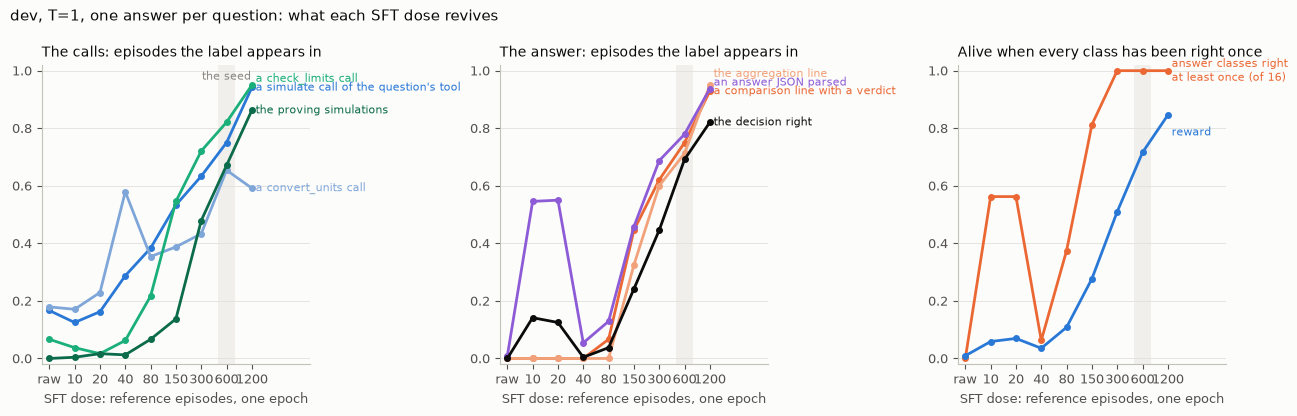

In [9]:
import matplotlib.pyplot as plt


def dodge(ys, gap=0.03):
    order_ = sorted(range(len(ys)), key=lambda i: ys[i])
    out = list(ys)
    for a, b in zip(order_, order_[1:]):
        out[b] = max(out[b], out[a] + gap)
    return out


xs = list(doses)
ticks = ["raw" if n == 0 else str(n) for n in xs]
panels = [("The calls", [(LABELS[1], "#2a78d6"), (LABELS[2], "#7fa6d8"), (LABELS[3], "#1baf7a"), (LABELS[4], "#0b6b4a")]),
          ("The answer", [(LABELS[5], "#eb6834"), (LABELS[6], "#f2a27a"), (LABELS[7], "#8e5bd6"), (LABELS[8], "#0b0b0b")])]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), facecolor="#fcfcfb")
for ax in axes:
    ax.set_facecolor("#fcfcfb")
    ax.grid(axis="y", color="#e1e0d9", lw=0.6)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)
    for s_ in ("left", "bottom"):
        ax.spines[s_].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", labelsize=9)
    ax.set_xticks(range(len(xs)), ticks)
    ax.set_xlabel("SFT dose: reference episodes, one epoch", fontsize=9, color="#52514e")
    ax.set_xlim(-0.3, len(xs) - 0.3 + 1.6)
for ax, (title, series) in zip(axes, panels):
    ends = []
    for label, color in series:
        ys = [doses[n][0]["rate"][label] for n in xs]
        ax.plot(range(len(xs)), ys, color=color, lw=2, marker="o", ms=4)
        ends.append(ys[-1])
    for (label, color), y in zip(series, dodge(ends)):
        ax.text(len(xs) - 0.85, y, label.replace(", ran", "").replace(" (scan questions)", ""), color=color, fontsize=8, va="center")
    ax.set_ylim(-0.02, 1.02)
    ax.set_title(f"{title}: episodes the label appears in", fontsize=10, color="#0b0b0b", loc="left")
ax = axes[2]
ax.plot(range(len(xs)), [sum(1 for v in doses[n][0]["classes"].values() if v[0] > 0) / 16 for n in xs], color="#eb6834", lw=2, marker="o", ms=4)
ax.plot(range(len(xs)), [doses[n][1]["reward"] for n in xs], color="#2a78d6", lw=2, marker="o", ms=4)
ax.text(len(xs) - 0.85, sum(1 for v in doses[xs[-1]][0]["classes"].values() if v[0] > 0) / 16, "answer classes right\nat least once (of 16)", color="#eb6834", fontsize=8, va="center")
ax.text(len(xs) - 0.85, doses[xs[-1]][1]["reward"] - 0.06, "reward", color="#2a78d6", fontsize=8, va="center")
ax.set_ylim(-0.02, 1.02)
ax.set_title("Alive when every class has been right once", fontsize=10, color="#0b0b0b", loc="left")
chosen_i = xs.index(int(SEED06.split("-n")[1]))
for ax in axes:
    ax.axvspan(chosen_i - 0.35, chosen_i + 0.35, color="#f0efec", lw=0, zorder=0)
axes[0].text(chosen_i, 1.0, "the seed", ha="center", va="top", fontsize=8, color="#898781")
fig.suptitle("dev, T=1, one answer per question: what each SFT dose revives", fontsize=10.5, color="#0b0b0b", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(HERE / "06_direction_and_compare_doses.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

In [10]:
def recall(path, cs):
    rec = collections.defaultdict(lambda: [0, 0])
    for r in rows_of(path):
        c = cs[r["id"]]
        cls = nw.decision_class(c) or c["gold"]["decision"]
        rec[(c["family"], cls)][1] += 1
        rec[(c["family"], cls)][0] += r["score"]["decision_correct"]
    return rec


X2 = RUNS / SEED06 / CKPT06 / "dev-T1-x2-stop.episodes.jsonl"
for name, path, cs in ((f"06's seed ({SEED06}), dev T=1 {'x2' if X2.exists() else 'x1'}", X2 if X2.exists() else X2.with_name("dev-T1-stop.episodes.jsonl"), dev06),
                       ("05's label seed, dev T=1 x2", RUNS05 / "label-seed-pc2" / "epoch3" / "dev-T1-x2-stop.episodes.jsonl", dev05)):
    o = json.loads(Path(path).with_name(Path(path).name.replace(".episodes.jsonl", ".json")).read_text())["overall"]
    print(f"== {name}: reward {o['reward']:.3f}, decisions {o['decision_correct']:.3f}, proving simulations {o['evidence']:.3f}, "
          f"answers {o['answer_found']:.3f}, calls/episode {o['calls_per_episode']:.2f} (errored {o['calls_errored']:.3f}), "
          f"converts/episode {o.get('converts_per_episode', 0):.2f}, checks/episode {o.get('compares_per_episode', 0):.2f}")
    show(name, path, cs)
    print()

order = [("ro_check", "fail"), ("ro_check", "pass"), ("swro_check", "fail"), ("swro_check", "pass"),
         ("ro_membrane", "A"), ("ro_membrane", "B"), ("ro_membrane", "C"), ("ro_membrane", "none"),
         ("swro_option", "A"), ("swro_option", "B"), ("swro_option", "C"), ("swro_option", "none"),
         ("ro_scan_area", "setting"), ("ro_scan_area", "none"), ("ro_scan_pressure", "setting"), ("ro_scan_pressure", "none")]
r06 = recall(X2 if X2.exists() else X2.with_name("dev-T1-stop.episodes.jsonl"), dev06)
r05 = recall(RUNS05 / "label-seed-pc2" / "epoch3" / "dev-T1-x2-stop.episodes.jsonl", dev05)
print(f"{'family':17} {'answer':8} {'05 seed':>10} {'06 seed':>10}   (right / sampled, T=1, {'two' if X2.exists() else '05: two, 06: one'} per dev question)")
for key in order:
    print(f"{key[0]:17} {key[1]:8} {r05[key][0]:>5}/{r05[key][1]:<4} {r06[key][0]:>5}/{r06[key][1]:<4}")

== 06's seed (label-seed-n600), dev T=1 x2: reward 0.702, decisions 0.683, proving simulations 0.648, answers 0.792, calls/episode 3.85 (errored 0.528), converts/episode 1.94, checks/episode 0.90
== 06's seed (label-seed-n600), dev T=1 x2
   items                                          1843
   verdict right                                  1794
   verdict wrong: limit wrong                     1
   verdict wrong: value wrong                     47
   verdict wrong: operator wrong                  0
   verdict wrong: comparison                      1
   limits needing conversion                      87
     written right                                86
     the user's number copied                     0
   wrong decisions                                152
     no answer                                    100
     proving simulation missing                   40
     after the right simulations                  12
   scan wrong after right sims                    5
     a verdict wro

family            answer      05 seed    06 seed   (right / sampled, T=1, two per dev question)
ro_check          fail        44/44      33/44  
ro_check          pass        33/36      21/36  
swro_check        fail        34/34      29/34  
swro_check        pass        41/46      35/46  
ro_membrane       A           21/22      18/22  
ro_membrane       B           26/26      20/26  
ro_membrane       C            9/10       5/10  
ro_membrane       none        22/22      17/22  
swro_option       A           16/20      10/20  
swro_option       B           32/34      22/34  
swro_option       C           16/18      12/18  
swro_option       none         7/8        8/8   
ro_scan_area      setting     57/68      43/68  
ro_scan_area      none         9/12       8/12  
ro_scan_pressure  setting     58/64      37/64  
ro_scan_pressure  none        14/16      10/16  


## PPO

05's configuration, unchanged except for its start, its stopping rules and, in one run each, lambda, the unit of credit and the actor step: each run starts from an alive dose's
seed, the tool gate is off (the runs with it on, which it stopped within 38 actor steps, head the table), and the
answer-collapse rule is on. The runs, by the seed they start from, then by what changed:

| PPO from | tool gate | lambda, per | the run ended | best evaluation | the 120 dev questions at the evaluations, every 25 steps |
| --- | --- | --- | --- | --- | --- |
| the 300-episode seed | on: 0.10 below the warm-up mean | 0.95 per token | step 63 -- tool gate (relative): sampled call fidelity over the last 10 steps 0.703 < the warm-up mean 0.809 - 0.10 | step 0, 0.605 | 0.605, 0.605, 0.489 |
| the 600-episode seed | on: 0.10 below the warm-up mean | 0.95 per token | step 45 -- tool gate (relative): sampled call fidelity over the last 10 steps 0.782 < the warm-up mean 0.891 - 0.10 | step 0, 0.879 | 0.879, 0.879 |
| the 600-episode seed | off | 0.95 per token | step 121 -- answer collapse: sampled answered rate over the last 10 steps 0.388 < 0.5 x the warm-up mean 0.820 | step 0, 0.879 | 0.879, 0.879, 0.677, 0.569, 0.560 |
| the 600-episode seed | off | 1 per token | step 200 -- converged: 8 evaluations without beating 0.8795 (step 0) | step 0, 0.879 | 0.879, 0.879, 0.555, 0.820, 0.793, 0.800, 0.795, 0.783, 0.793 |
| the 600-episode seed | off | 0.95 per turn | step 150 -- critic gate: value_ev not above the position clock at two evaluations | step 0, 0.879 | 0.879, 0.879, 0.870, 0.813, 0.568, 0.000, 0.000 |
| the 600-episode seed | off | 0.95 per turn, actor lr 2e-6 | step 200 -- converged: 8 evaluations without beating 0.8795 (step 0) | step 0, 0.879 | 0.879, 0.879, 0.809, 0.826, 0.829, 0.809, 0.848, 0.845, 0.847 |
| the 1200-episode seed | off | 0.95 per token | step 200 -- converged: 8 evaluations without beating 0.9467 (step 0) | step 0, 0.947 | 0.947, 0.947, 0.926, 0.870, 0.898, 0.906, 0.900, 0.868, 0.788 |

| setting | value | from |
| --- | --- | --- |
| start | an alive dose's seed; value head warm-started at that seed's sampled dev reward (0.702 for 600, 0.840 for 1200) | above |
| critic | value head on hidden layer 23, lr 9.19e-4; 25 steps with the actor frozen (the warm-up, which also sets the rules' baseline) | `02`, `04` |
| actor | LoRA r16, lr 1e-5 (the fourth run from the seed: 2e-6, a fifth), 4 inner epochs, clip 0.2; 8 train questions per step at T=1; gamma 1, lambda 0.95 per token (`ppo-n600-open-s0`, `ppo-n1200-open-s0`); lambda 1 per token (`ppo-n600-open-lam1-s0`); lambda 0.95 per turn (`ppo-n600-open-turn-s0`); lambda 0.95 per turn at actor lr 2e-6 (`ppo-n600-open-turn-lr2e6-s0`) | `03`, here |
| what the actor moves | the calls turns and, in the answer, its content: values, limits, verdicts, the aggregation line's set and pick, the decision, the violations, the numbers | `03`, `05` |
| stabilisers | Adam eps 1e-6; KL 0.01 to the seed in the reward; answers stopped at their closing brace; turn-ending `<|im_end|>` out of the loss | `03` |
| rules | tool gate off -- the runs with it on head the table above; answer collapse: the last 10 steps' answered rate below 0.5 x the warm-up mean, judged once that mean is 0.2 or more; no-regression gate off; critic gate: from step 40, the critic not ahead of the position clock at two evaluations; convergence: 8 evaluations without a new best; one evaluation of 120 dev questions every 25 steps | `03`, `04`, here |

In [11]:
import json
import matplotlib.pyplot as plt

train_cases = cases_of("train")
W = 25
SAMPLED = [LABELS[1], LABELS[2], LABELS[3], LABELS[5], LABELS[6], LABELS[7]]
LOCAL = set(nw.LOCAL_TOOLS)


def cv_args(c):
    a = c["arguments"]
    if isinstance(a, str):
        try:
            a = json.loads(a)
        except Exception:
            a = {}
    return a or {}


def convert_shape(x):
    """(converts of a value already in the tool's units to themselves, identical convert calls repeated) in one episode."""
    cv = [cv_args(c) for c in x["calls"] if c["name"] == nw.CONVERT]
    same = sum(1 for a in cv if str(a.get("from_unit")) == str(a.get("to_unit")))
    return same, len(cv) - len({json.dumps(a, sort_keys=True) for a in cv})


def first_turn_blocks(x):
    """Tool-call blocks written in the first turn, executed or not (a turn that never ended executed none of them)."""
    t = x["turns"][0] if x["turns"] else ""
    return t.count("<tool_call>") if isinstance(t, str) else 0


def raw_first(x):
    """The first simulate call of an episode: how many of its arguments are a number the question states in another unit,
    passed unconverted -- equal (within 1%) to the question's own value while the gold argument differs from that value by
    more than 1%. Inputs the question states as SI permeabilities (A_comp, B_comp) are skipped."""
    sims = sims_of(x)
    if not sims:
        return 0
    a, case = cv_args(sims[0]), train_cases[x["id"]]
    gold = case["points"][0]["args"] if case.get("points") else {}
    n = 0
    for k, inp in case.get("inputs", {}).items():
        v, u, g = a.get(k), inp.get("user_value"), gold.get(k)
        if inp.get("unit") == "SI" or not all(isinstance(t, (int, float)) and not isinstance(t, bool) for t in (v, u, g)) or g == 0 or u == 0:
            continue
        if abs(g - u) <= 0.01 * abs(g):          # the question already states this input in the tool's units
            continue
        if abs(v - u) <= 0.01 * abs(u):
            n += 1
    return n


def converted_used(x):
    """(values converted, of them used): a converted value (not same-unit, the conversion succeeded) counts as used when it appears
    within 1% among the arguments of a later simulate call of the episode."""
    n = u = 0
    for i, c in enumerate(x["calls"]):
        if c["name"] != nw.CONVERT:
            continue
        a = cv_args(c)
        if str(a.get("from_unit")) == str(a.get("to_unit")):
            continue
        try:
            d = json.loads(nw.convert_units(a.get("value"), a.get("from_unit"), a.get("to_unit")))
        except Exception:
            continue
        if not isinstance(d, dict) or "value" not in d:
            continue
        v = float(d["value"]); later = []
        for cc in x["calls"][i + 1:]:
            if cc["name"] in LOCAL:
                continue
            for y in cv_args(cc).values():
                try:
                    later.append(float(y))
                except Exception:
                    pass
        n += 1; u += any(abs(v - y) <= 0.01 * max(abs(v), 1e-12) for y in later)
    return n, u


def load_run(name):
    run = RUNS / name
    return {"name": name, "dir": run, "dose": int(re.match(r"ppo-n(\d+)", name).group(1)), "evals": rows_of(run / "eval.jsonl"),
            "metrics": rows_of(run / "metrics.jsonl"), "samples": rows_of(run / "samples.jsonl") if (run / "samples.jsonl").exists() else [],
            "ending": json.loads((run / "ending.json").read_text()), "cfg": json.loads((run / "config.json").read_text())}


def windows_of(R):
    """Per 25-step window of a run: call fidelity, the proving simulations, the decision and the answered rate are per-step
    means from the metrics; the other labels are read from the sampled episodes (every step's eight when sample_every is 1)."""
    wins = []
    for a in range(0, R["ending"]["stopped_at"] + 1, W):
        ms = [r for r in R["metrics"] if a <= r["step"] < a + W]
        if not ms:
            continue
        w = {"from": a, "to": min(a + W - 1, R["ending"]["stopped_at"]), "mid": a + W / 2, "n": len(ms),
             "call fidelity": st.mean(r["calls_fidelity"] for r in ms), LABELS[4]: st.mean(r["evidence"] for r in ms),
             LABELS[8]: st.mean(r["decision_correct"] for r in ms), "answered": st.mean(r["answered"] for r in ms),
             "truncated": st.mean(r["truncated"] for r in ms), "reward": st.mean(r["reward_mean"] for r in ms),
             "kl": st.mean(r["kl_mean"] for r in ms), "s/step": st.mean(r["step_seconds"] for r in ms),
             "adv sd": st.mean([r["adv_std"] for r in ms if r.get("adv_std") is not None] or [float("nan")]),
             "ev": st.mean([r["value_ev"] for r in ms if r.get("value_ev") is not None] or [float("nan")])}
        ss = [x for x in R["samples"] if a <= x["step"] < a + W]
        if ss:
            L = labels_of(ss, train_cases, scored=False)
            w.update({k: L["rate"][k] for k in SAMPLED}); w["sampled"] = L["n"]
        wins.append(w)
    return wins


def sims_of(x):
    return [c for c in x["calls"] if c["name"] not in LOCAL]


def whole_right(x):
    """(decision right, whole answer right) of a sampled episode: the decision right; and, with it, every reported number within VALUE_TOL
    of the gold and, on pass/fail questions, the violations list exact -- the held-out tables' 'whole answer right', read on the training samples."""
    case = train_cases[x["id"]]
    ans, _, _ = nw.extract_answer(x["final_text"])
    if not ans:
        return 0.0, 0.0
    dec = bool(nw.decision_correct(case, ans.get("decision")))
    pv = nw.flatten(ans.get("values"))
    vals_ok = all((lambda t: t is not None and abs(t - g) <= nw.VALUE_TOL * abs(g))(nw.parse_number(pv.get(p))) for p, g in case["gold"]["values"].items())
    viol_ok = True
    if case["decision_kind"] == "passfail":
        pred = ans.get("violations")
        viol_ok = isinstance(pred, list) and {str(v).strip() for v in pred} == set(case["gold"]["violations"])
    return float(dec), float(dec and vals_ok and viol_ok)


def level_stats(samples, a, b):
    """The sampled episodes of steps a..b by the question's unit level (0: every input in the tool's own units; 1 and 2:
    one or more inputs in other units), plus levels 1 and 2 together and all: convert calls per episode, the share of
    episodes with a convert call, the first simulate call's error rate, the error rate of all simulate calls, calls per
    episode, answered, reward, truncated; and where the convert calls go: converts of a value already in the tool's units, identical
    convert calls repeated, tool-call blocks written in the first turn, episodes whose first turn ran to the token budget before it
    ended (nothing executed, no answer); and the share of episodes whose first simulate call passed a number the question states
    in another unit unconverted (the question's own number as the argument), also among the episodes whose first simulate call errored;
    whole answers right (the held-out tables' measure, on the training samples) and the share of episodes that ended with an empty final
    turn (no answer written, not cut at the token budget)."""
    out = {}
    ss = [x for x in samples if a <= x["step"] <= b]
    for lvl in (0, 1, 2, "1+2", "all"):
        R_ = [x for x in ss if lvl == "all" or (train_cases[x["id"]]["level"] > 0 if lvl == "1+2" else train_cases[x["id"]]["level"] == lvl)]
        if not R_:
            continue
        sims = [c for x in R_ for c in sims_of(x)]
        out[lvl] = {"n": len(R_), "conv/ep": st.mean(sum(c["name"] == nw.CONVERT for c in x["calls"]) for x in R_),
                    "any convert": st.mean(float(any(c["name"] == nw.CONVERT for c in x["calls"])) for x in R_),
                    "first simulate errored": st.mean(float(bool(sims_of(x)) and sims_of(x)[0]["error"]) for x in R_),
                    "simulate errored": st.mean(float(c["error"]) for c in sims) if sims else float("nan"),
                    "calls/ep": st.mean(len(x["calls"]) for x in R_), "answered": st.mean(float(x["answer_closed"]) for x in R_),
                    "reward": st.mean(x["reward"] for x in R_), "truncated": st.mean(float(x["truncated"]) for x in R_),
                    "same-unit convert/ep": st.mean(convert_shape(x)[0] for x in R_), "repeated convert/ep": st.mean(convert_shape(x)[1] for x in R_),
                    "first-turn blocks": st.mean(first_turn_blocks(x) for x in R_),
                    "no-call truncated": st.mean(float(x["truncated"] and not x["calls"]) for x in R_),
                    "first call raw": st.mean(float(raw_first(x) > 0) for x in R_)}
        er = [x for x in R_ if sims_of(x) and sims_of(x)[0]["error"]]
        out[lvl]["raw among first errors"] = st.mean(float(raw_first(x) > 0) for x in er) if er else float("nan")
        rw = [x for x in R_ if raw_first(x) > 0]
        out[lvl]["raw and converted"] = st.mean(float(any(c["name"] == nw.CONVERT for c in x["calls"])) for x in rw) if rw else float("nan")
        cu = [converted_used(x) for x in R_]
        out[lvl]["converted used"] = sum(u for _, u in cu) / sum(n for n, _ in cu) if sum(n for n, _ in cu) else float("nan")
        wr = [whole_right(x) for x in R_]
        out[lvl]["decision right"], out[lvl]["whole right"] = st.mean(d for d, _ in wr), st.mean(w for _, w in wr)
        out[lvl]["empty answer"] = st.mean(float(x["unanswered"] and not x["truncated"]) for x in R_)
    return out


def level_table(R, levels=(0, 1, 2, "all")):
    every = "every step's eight" if R["cfg"]["sample_every"] == 1 else f"every {R['cfg']['sample_every']}th step's eight"
    print(f"\n{R['name']}: the sampled episodes by unit level, per {W} steps ({every})")
    print(f"{'steps':>9} {'level':>5} {'n':>4} {'conv/ep':>8} {'anyConv':>8} {'sim1Err':>8} {'raw1st':>7} {'simErr':>7} {'calls/ep':>9} {'answered':>9} {'whole':>6} {'reward':>7} {'trunc':>6}")
    for a in range(0, R["ending"]["stopped_at"] + 1, W):
        b = min(a + W - 1, R["ending"]["stopped_at"])
        L = level_stats(R["samples"], a, b)
        for lvl in levels:
            if lvl in L:
                s = L[lvl]
                print(f"{a:>4}-{b:<4} {str(lvl):>5} {s['n']:>4} {s['conv/ep']:>8.2f} {s['any convert']:>8.2f} {s['first simulate errored']:>8.2f} "
                      f"{s['first call raw']:>7.2f} {s['simulate errored']:>7.2f} {s['calls/ep']:>9.2f} {s['answered']:>9.2f} {s['whole right']:>6.2f} {s['reward']:>7.3f} {s['truncated']:>6.2f}")


def convert_table(R, levels=(0, 1, 2, "all")):
    """Where the convert calls go, per 25 steps and unit level: convert calls per episode, converts of a value already in the tool's
    units to itself, identical convert calls repeated, tool-call blocks written in the first turn (executed or not), episodes whose
    first turn ran to the token budget before it ended (nothing executed, no answer, reward 0), truncated, and the share of the converted
    values a later simulate call used."""
    print(f"\n{R['name']}: the convert calls by unit level, per {W} steps")
    print(f"{'steps':>9} {'level':>5} {'n':>4} {'conv/ep':>8} {'sameUnit':>9} {'repeated':>9} {'blocks1st':>9} {'noCallTr':>9} {'trunc':>6} {'convUsed':>8}")
    for a in range(0, R["ending"]["stopped_at"] + 1, W):
        b = min(a + W - 1, R["ending"]["stopped_at"])
        L = level_stats(R["samples"], a, b)
        for lvl in levels:
            if lvl in L:
                s = L[lvl]
                print(f"{a:>4}-{b:<4} {str(lvl):>5} {s['n']:>4} {s['conv/ep']:>8.2f} {s['same-unit convert/ep']:>9.2f} {s['repeated convert/ep']:>9.2f} "
                      f"{s['first-turn blocks']:>9.1f} {s['no-call truncated']:>9.2f} {s['truncated']:>6.2f} {s['converted used']:>8.2f}")


def paired_levels(Ra, Rb, lvl="1+2"):
    """Two runs side by side, per 25-step window, on the level-1-and-2 questions (the ones with a unit to convert)."""
    upto = max(Ra["ending"]["stopped_at"], Rb["ending"]["stopped_at"])
    print(f"\nlevels 1 and 2 per {W} steps: {Ra['name']} (lambda {Ra['cfg']['lam']:g} per {Ra['cfg'].get('adv_unit', 'token')}{lr_note(Ra['cfg'])}) | "
          f"{Rb['name']} (lambda {Rb['cfg']['lam']:g} per {Rb['cfg'].get('adv_unit', 'token')}{lr_note(Rb['cfg'])})")
    cols = ["n", "conv/ep", "same-unit convert/ep", "any convert", "first simulate errored", "answered", "reward", "calls/ep"]
    short = {"n": "n", "conv/ep": "conv/ep", "same-unit convert/ep": "sameU", "any convert": "anyConv", "first simulate errored": "sim1Err",
             "answered": "ans", "reward": "reward", "calls/ep": "calls"}
    print(f"{'steps':>9} | " + " ".join(f"{short[c]:>7}" for c in cols) + " | " + " ".join(f"{short[c]:>7}" for c in cols))
    for a in range(0, upto + 1, W):
        parts, Ls = [], []
        for R in (Ra, Rb):
            L = level_stats(R["samples"], a, a + W - 1).get(lvl); Ls.append(L)
            parts.append(" ".join(f"{L[c]:>7.{0 if c == 'n' else 2}f}" if L else f"{'-':>7}" for c in cols))
        if any(Ls):
            print(f"{a:>4}-{min(a + W - 1, upto):<4} | " + " | ".join(parts))


def decision_distance(R):
    """Level 1-2 episodes: the first turn's length in policy tokens, by what its first call was. The convert-or-simulate
    choice is made at the turn's start; the tool's answer (the error, when the raw number went in) comes after the
    whole turn, and a TD error d tokens later reaches a token's advantage weighted (gamma x lambda)^d."""
    d = collections.defaultdict(list)
    for x in R["samples"]:
        if train_cases[x["id"]]["level"] == 0 or not x["calls"]:
            continue
        key = "simulate first" if x["calls"][0]["name"] not in LOCAL else "convert first"
        d[key].append(len(tok(x["turns"][0], add_special_tokens=False).input_ids))
    lam = R["cfg"]["lam"]
    for key in ("convert first", "simulate first"):
        if key in d:
            med = st.median(d[key])
            print(f"  {key:>14}: {len(d[key]):>4} episodes, first turn median {med:.0f} policy tokens; (gamma x lambda)^{med:.0f} = {(R['cfg']['gamma'] * lam) ** med:.1e} at lambda {lam:g}")


def critic_by_level(R):
    """The critic's value at the first policy token of each sampled episode (its estimate before anything is written),
    by unit level, against the episodes' rewards. Recovered from the critic window saved with the run's last checkpoint
    (the values and returns of its last 25 steps), aligned with the sampled episodes of those steps."""
    p = R["dir"] / "last" / "state.pt"
    if not p.exists():
        print("  no last/state.pt"); return
    import torch
    s_ = torch.load(p, map_location="cpu", weights_only=False)
    first = s_["step"] - len(s_["window"])
    win = {first + k: (w[1].float(), w[2].float()) for k, w in enumerate(s_["window"])}
    del s_
    v0, rew, ret = collections.defaultdict(list), collections.defaultdict(list), collections.defaultdict(list)
    by_step = collections.defaultdict(list)
    for x in R["samples"]:
        if x["step"] in win:
            by_step[x["step"]].append(x)
    aligned = misaligned = 0
    for step, xs in sorted(by_step.items()):
        vals, rets = win[step]
        if sum(x["policy_tokens"] for x in xs) != len(vals):
            misaligned += 1; continue
        off = 0
        for x in xs:
            lvl = train_cases[x["id"]]["level"]
            v0[lvl].append(float(vals[off])); ret[lvl].append(float(rets[off])); rew[lvl].append(x["reward"]); off += x["policy_tokens"]
            aligned += 1
    print(f"  steps {min(win)}-{max(win)} of the window; {aligned} sampled episodes aligned, {misaligned} steps not")
    print(f"  {'level':>5} {'n':>4} {'V at token 0':>13} {'return':>8} {'reward':>8}")
    for lvl in sorted(v0):
        print(f"  {lvl:>5} {len(v0[lvl]):>4} {st.mean(v0[lvl]):>13.3f} {st.mean(ret[lvl]):>8.3f} {st.mean(rew[lvl]):>8.3f}")


def dodge(ys, gap=0.035):
    order_ = sorted(range(len(ys)), key=lambda i: ys[i])
    out = list(ys)
    for a, b in zip(order_, order_[1:]):
        out[b] = max(out[b], out[a] + gap)
    return out


def lr_note(cfg):
    """', actor lr 2e-6' when a run's actor learning rate is not the series' 1e-5; '' otherwise."""
    lr = cfg.get("lr", 1e-5)
    return "" if lr == 1e-5 else f", actor lr {lr:.0e}".replace("e-0", "e-")


def report_run(R, fig_name):
    evals, metrics, samples, ending, cfg = R["evals"], R["metrics"], R["samples"], R["ending"], R["cfg"]
    gate_txt = ", tool gate off" if not cfg["tool_stop_rel"] and not cfg["tool_stop"] else ""
    print(f"== {R['name']}: lambda {cfg['lam']:g} per {cfg.get('adv_unit', 'token')}{lr_note(cfg)}{gate_txt}")
    print(ending)
    print(f"\n{'step':>5} {'reward':>7} {'decision':>9} {'proving':>8} {'answers':>8} {'violations':>11} {'values':>7} {'errored':>8} {'critic - clock':>15}")
    for e in evals:
        c = e["components"]
        crit = e["critic_residual_median"]
        print(f"{e['step']:>5} {e['reward']:>7.3f} {e['decision_correct']:>9.3f} {e['evidence']:>8.3f} {e['answer_found']:>8.3f} {c['violations']:>11.3f} "
              f"{c['values']:>7.3f} {e['calls_errored']:>8.3f} {'-' if crit is None else f'{crit:+.3f}':>15}")
    wins = windows_of(R)
    print(f"\n{'steps':>9} {'reward':>7} {'fidelity':>9} {'sim ran':>8} {'convert':>8} {'check':>6} {'proving':>8} {'compare':>8} {'aggreg.':>8} {'answer':>7} {'decision':>9} {'trunc':>6} {'KL':>7} {'adv sd':>7} {'ev':>6} {'s/step':>7}")
    nz = lambda v, fmt: "-" if v != v else format(v, fmt)   # the actor's advantage spread per token and the critic's explained variance, per-step means (none in the warm-up)
    for w in wins:
        f = lambda k: f"{w[k]:.3f}" if k in w else "-"
        print(f"{w['from']:>4}-{w['to']:<4} {w['reward']:>7.3f} {w['call fidelity']:>9.3f} {f(LABELS[1]):>8} {f(LABELS[2]):>8} {f(LABELS[3]):>6} {w[LABELS[4]]:>8.3f} "
              f"{f(LABELS[5]):>8} {f(LABELS[6]):>8} {w['answered']:>7.3f} {w[LABELS[8]]:>9.3f} {w['truncated']:>6.3f} {w['kl']:>7.4f} {nz(w['adv sd'], '.2f'):>7} {nz(w['ev'], '.2f'):>6} {w['s/step']:>7.0f}")
    # The calls themselves, from the sampled episodes: how many per episode, how many errored, how many repeat an earlier
    # call of the episode exactly (same tool, same arguments), and how the episodes end.
    print(f"\n{'steps':>9} {'calls/ep':>9} {'errored':>8} {'identical repeats/ep':>21} {'turns/ep':>9} {'tokens':>7} {'truncated':>10} {'unanswered':>11}")
    for w in wins:
        ss = [x for x in samples if w["from"] <= x["step"] <= w["to"]]
        if not ss:
            continue
        calls_ = [c_ for x in ss for c_ in x["calls"]]
        rep_ = sum(v - 1 for x in ss for v in collections.Counter(json.dumps(c_["arguments"], sort_keys=True) + str(c_["name"]) for c_ in x["calls"]).values())
        print(f"{w['from']:>4}-{w['to']:<4} {len(calls_) / len(ss):>9.2f} {sum(c_['error'] for c_ in calls_) / max(1, len(calls_)):>8.2f} {rep_ / len(ss):>21.2f} "
              f"{st.mean(len(x['turns']) for x in ss):>9.1f} {st.mean(x['policy_tokens'] for x in ss):>7.0f} {st.mean(float(x['truncated']) for x in ss):>10.3f} {st.mean(float(x['unanswered']) for x in ss):>11.3f}")
    ahead = [r for r in metrics if r["step"] >= 25 and r["value_ev"] is not None and r["value_ev_position"] is not None]
    print(f"\nactor steps where the critic explains the return better than the position clock: "
          f"{sum(r['value_ev'] > r['value_ev_position'] for r in ahead)}/{len(ahead)}")

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True, facecolor="#fcfcfb")
    xmax = ending["stopped_at"] + 60 if ending["stopped_at"] < 150 else max(ending["stopped_at"] + 110, 300)
    for ax in axes:
        ax.set_facecolor("#fcfcfb")
        ax.axvspan(0, 25, color="#f0efec", lw=0)
        ax.grid(axis="y", color="#e1e0d9", lw=0.6)
        for s_ in ("top", "right"):
            ax.spines[s_].set_visible(False)
        for s_ in ("left", "bottom"):
            ax.spines[s_].set_color("#c3c2b7")
        ax.tick_params(colors="#52514e", labelsize=9)
        ax.set_xlabel("PPO step", fontsize=9, color="#52514e")
        ax.text(12.5, 0.01, "critic\nwarm-up", ha="center", va="bottom", fontsize=7.5, color="#898781")
        ax.set_xlim(-10, xmax)
        ax.axvline(ending["best_step"], color="#898781", lw=1, ls="--")
    axes[0].set_ylim(-0.02, 1.02)
    xs = [e["step"] for e in evals]
    ev_series = [("reward", "#2a78d6", [e["reward"] for e in evals]), ("decision right", "#eb6834", [e["decision_correct"] for e in evals]),
                 ("proving simulations", "#1baf7a", [e["evidence"] for e in evals]), ("answers that parse", "#8e5bd6", [e["answer_found"] for e in evals])]
    for label, color, ys in ev_series:
        axes[0].plot(xs, ys, color=color, lw=2, marker="o", ms=3.5)
    for (label, color, ys), y in zip(ev_series, dodge([ys[-1] for _, _, ys in ev_series])):
        axes[0].text(xs[-1] + 6, y, label, color=color, fontsize=8, va="center")
    axes[0].text(ending["best_step"] + 4, 0.97, f"best (step {ending['best_step']})", color="#52514e", fontsize=8)
    axes[0].set_title("Held out: 120 dev questions, greedy", fontsize=10, color="#0b0b0b", loc="left")
    wx = [w["mid"] for w in wins]
    call_series = [("call fidelity", "#0b0b0b", "call fidelity"), ("simulate call ran", "#2a78d6", LABELS[1]), ("convert call ran", "#7fa6d8", LABELS[2]),
                   ("check call ran", "#1baf7a", LABELS[3])]
    ans_series = [("comparison line", "#eb6834", LABELS[5]), ("aggregation line", "#f2a27a", LABELS[6]), ("answer JSON", "#8e5bd6", LABELS[7]),
                  ("proving simulations", "#1baf7a", LABELS[4]), ("decision right", "#0b0b0b", LABELS[8])]
    for ax, series, title in ((axes[1], call_series, "Training samples: the calls, per 25 steps"), (axes[2], ans_series, "Training samples: the answer, per 25 steps")):
        ends = []
        for label, color, key in series:
            pts = [(w["mid"], w[key]) for w in wins if key in w]
            ax.plot([p[0] for p in pts], [p[1] for p in pts], color=color, lw=2)
            ends.append(pts[-1][1] if pts else 0)
        for (label, color, key), y in zip(series, dodge(ends)):
            ax.text(wx[-1] + 6, y, label, color=color, fontsize=8, va="center")
        ax.set_title(title, fontsize=10, color="#0b0b0b", loc="left")
    fig.suptitle(f"PPO from the seed of {R['dose']} reference episodes, lambda {cfg['lam']:g} per {cfg.get('adv_unit', 'token')}{lr_note(cfg)}{gate_txt} -- {ending['reason']}",
                 fontsize=10.5, color="#0b0b0b", x=0.01, ha="left")
    fig.tight_layout()
    fig.savefig(HERE / fig_name, dpi=150, facecolor=fig.get_facecolor())
    plt.show()

### From the seed at 05's lambda 0.95: the run collapsed

**The run ended at step 121 (answer collapse, sampled answered rate over the last 10 steps 0.388 < 0.5 x the warm-up mean 0.820).** The evaluations on the 120 dev questions started at 0.8795 (decisions 0.875) and no later evaluation beat it. In the training samples, from the warm-up steps to the actor's steps 25-121: call fidelity 0.891 to 0.794, proving simulations 0.685 to 0.587, decisions 0.700 to 0.589, answers 0.820 to 0.665; comparison lines 0.750 to 0.694, aggregation lines 0.737 to 0.636, check calls that ran 0.825 to 0.719. The activation of each label over the run is the figure. The calls, from the warm-up to the last 25 steps: 7.0 to 9.0 per episode, 0.41 to 0.69 of them errored, 1.4 to 2.4 exact repeats of an earlier call per episode, 0.07 to 0.30 of the episodes cut at the token budget. Sampled at T=1 in training, the actor's steps 25-121 scored 0.623 against the warm-up's 0.722 (KL to the seed 0.0036 per token); greedy on the 120 dev questions, the evaluations after the warm-up scored 0.677, 0.569, 0.560 against 0.879 at the start. The best evaluation is step 0, the seed itself, so the seed's held-out numbers are this run's result.

== ppo-n600-open-s0: lambda 0.95 per token, tool gate off
{'stopped_at': 121, 'reason': 'answer collapse: sampled answered rate over the last 10 steps 0.388 < 0.5 x the warm-up mean 0.820', 'best_step': 0, 'best_reward': 0.8794788779709415}

 step  reward  decision  proving  answers  violations  values  errored  critic - clock
    0   0.879     0.875    0.850    0.917       0.894   0.864    0.358               -
   25   0.879     0.875    0.850    0.917       0.894   0.864    0.358          +0.081
   50   0.677     0.650    0.617    0.667       0.689   0.607    0.731          +0.183
   75   0.569     0.542    0.517    0.567       0.510   0.500    0.771          +0.083
  100   0.560     0.508    0.525    0.558       0.495   0.476    0.794          +0.076

    steps  reward  fidelity  sim ran  convert  check  proving  compare  aggreg.  answer  decision  trunc      KL  adv sd     ev  s/step
   0-24     0.722     0.891    0.750    0.525  0.825    0.685    0.750    0.737   0.820     0.700  

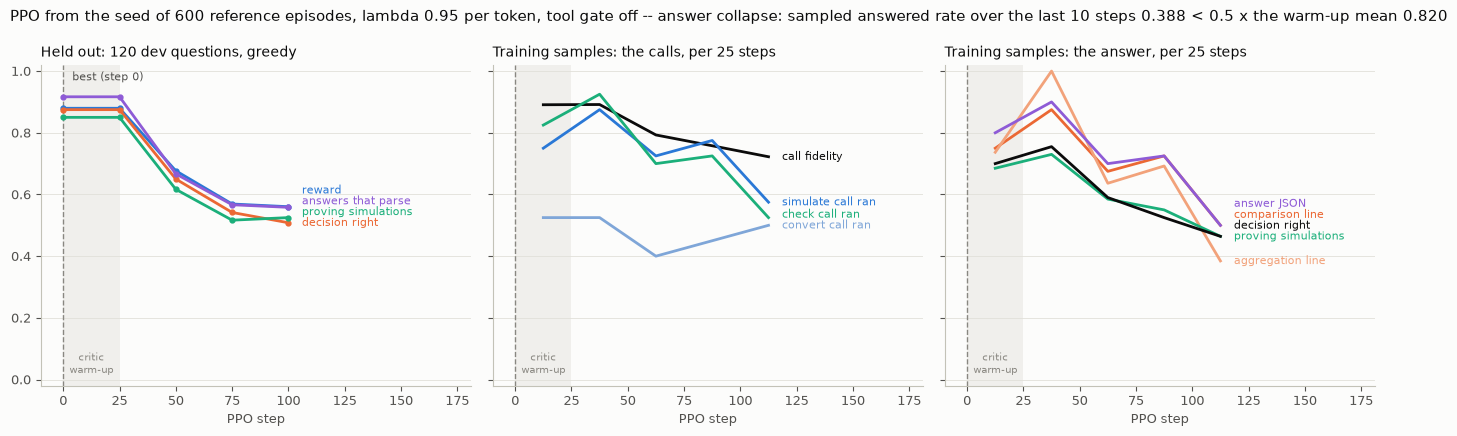

In [12]:
R_COLLAPSED = load_run("ppo-n600-open-s0")
report_run(R_COLLAPSED, "06_direction_and_compare_curves_lam095.png")

### Why it collapsed: the unit levels

The sampled episodes, split by the question's unit level, show what the run learned. On the level-0 questions, every input already in the tool's own units, it improved: reward 0.848 in the warm-up to 0.950 over the last 25 steps (97-121), 1.00 answered. On the level-1 and level-2 questions, one or more inputs in another unit, it converted less: convert calls per episode 1.44 to 1.06 on level 1 and 3.44 to 1.18 on level 2, the first simulate call erroring 0.33 to 0.69 and 0.67 to 0.73, answered 0.78 to 0.31 and 0.56 to 0.27. A simulate call fed the user's number in the user's unit is the error the seed recovers from by converting next; the collapsed policy repeats the call instead (the identical repeats in the table above). Two things in the setup let that habit grow. With lambda 0.95, a token's advantage is the sum of the TD errors after it weighted (gamma x lambda)^d, so a consequence d tokens later weighs 0.95^d: the first turn of a level-1-2 episode that opens with a simulate call runs a median 431 policy tokens before the tool answers -- the scan questions put their four or five simulate calls in one turn (the convert-first turns run 59) -- and 0.95^431 is 3e-10. The error's news never reaches the convert-or-simulate choice. The critic, whose value should carry that news instead, is blind to the level at the first token: V 0.760, 0.750, 0.742 for levels 0, 1, 2, whose episodes score 0.957, 0.554, 0.316 -- and so are the lambda-returns that token was trained toward, 0.768, 0.746, 0.722: at lambda 0.95 the target is the critic's own value a few tokens on, so the episode's reward never reaches it either (the critic window saved with the run's last checkpoint, steps 75-99, aligned with the sampled episodes of those steps). So at the choice the only signal was local, and the local signal does not tell the two paths apart. Lambda 1 is the fix that changes one variable: every token's advantage becomes the episode's return minus the critic's value, the error's news reaches the choice undiscounted, and a level-blind critic adds variance instead of hiding the level. A lambda that decays per turn rather than per token is the other way: the third run below makes the turn the unit of credit.

In [13]:
level_table(R_COLLAPSED)
print("\nthe first turn's length, level 1-2 episodes, by its first call:")
decision_distance(R_COLLAPSED)
print("\nthe critic at the first token, by unit level:")
critic_by_level(R_COLLAPSED)


ppo-n600-open-s0: the sampled episodes by unit level, per 25 steps (every 5th step's eight)
    steps level    n  conv/ep  anyConv  sim1Err  raw1st  simErr  calls/ep  answered  whole  reward  trunc
   0-24       0   22     1.05     0.18     0.05    0.00    0.20      4.50      0.91   0.77   0.848   0.00
   0-24       1    9     1.44     1.00     0.33    0.22    0.52      8.00      0.78   0.78   0.772   0.00
   0-24       2    9     3.44     1.00     0.67    0.67    0.85     12.33      0.56   0.22   0.335   0.33
   0-24     all   40     1.68     0.55     0.25    0.20    0.55      7.05      0.80   0.65   0.716   0.07
  25-49       0   20     0.15     0.05     0.00    0.00    0.00      3.50      1.00   0.95   0.943   0.00
  25-49       1   14     2.07     1.00     0.14    0.14    0.24      6.07      0.86   0.64   0.756   0.00
  25-49       2    6     3.17     1.00     0.50    0.17    0.88      8.17      0.67   0.50   0.616   0.00
  25-49     all   40     1.27     0.53     0.12    0.07    

  steps 75-99 of the window; 40 sampled episodes aligned, 0 steps not
  level    n  V at token 0   return   reward
      0   17         0.760    0.768    0.957
      1   16         0.750    0.746    0.554
      2    7         0.742    0.722    0.316


### One variable changed: lambda 1

`ppo-n600-open-lam1-s0` is `ppo-n600-open-s0` with lambda 1 and nothing else changed: the same seed, the same random seed (the same train questions in the same
order), the tool gate off, the answer-collapse rule at 0.5, no no-regression gate, 200 steps; every step's eight episodes are recorded
instead of every fifth step's. Its warm-up is the first run's warm-up byte for byte -- the same 25 x 8 episodes, the same per-step rewards -- so the two runs diverge only from the first actor update, and only through the advantage. Three criteria were written before it ran, all three to be met: (1) on the level-1 and level-2 questions, the share of sampled episodes with a convert call over the run's last 25 steps is not below the warm-up's; (2) the best evaluation is a checkpoint of its own, not step 0, and beats the start by more than the noise of 120 questions, 0.03; (3) that checkpoint, held out greedy, beats the seed on whole answers right on test and on holdout_shift (0.775 and 0.717). A caution for reading it: with lambda 1 every token's advantage carries the KL penalties of all the tokens after it, a pull toward shorter episodes; at this run's KL (0.0117 per token over 1,123 policy tokens an episode) they sum to 0.13 an episode on the reward's 0-to-1 scale, against 0.05 in the lambda-0.95 run.

**The run ended at step 200 (converged, 8 evaluations without beating 0.8795, step 0).** The evaluations on the 120 dev questions started at 0.8795 (decisions 0.875) and no later evaluation beat it. In the training samples, from the warm-up steps to the actor's steps 25-200: call fidelity 0.891 to 0.895, proving simulations 0.685 to 0.745, decisions 0.700 to 0.766, answers 0.820 to 0.850; comparison lines 0.755 to 0.825, aggregation lines 0.767 to 0.783, check calls that ran 0.825 to 0.836. The activation of each label over the run is the figure. The calls, from the warm-up to the last 25 steps: 7.0 to 7.4 per episode, 0.36 to 0.39 of them errored, 1.2 to 1.4 exact repeats of an earlier call per episode, 0.04 to 0.07 of the episodes cut at the token budget. Sampled at T=1 in training, the actor's steps 25-200 scored 0.773 against the warm-up's 0.722 (KL to the seed 0.0117 per token); greedy on the 120 dev questions, the evaluations after the warm-up scored 0.555, 0.820, 0.793, 0.800, 0.795, 0.783, 0.793 against 0.879 at the start. The best evaluation is step 0, the seed itself, so the seed's held-out numbers are this run's result.

**What it did.** The credit reached the decision this time, and the run went the other way: on the level-1 and level-2 questions, convert calls per episode 2.69 in the warm-up rose to 5.82 over steps 25-49, 1.28 per episode converting a value already in the tool's units to itself (0.05 in the warm-up) and 0.50 repeating a call already made (0.16), the first turn writing 8.8 tool-call blocks (2.6); 0.05 of those episodes spent the whole 3,072-token budget inside the first turn, one unbroken stream of convert calls that never ended the turn -- nothing executed, no answer, reward 0. The greedy evaluation at step 50 fell to 0.555 with 0.35 of the episodes cut at the token budget (0.04 at step 0). Over the last 25 steps the stream was gone (0.00 of the episodes) and the convert calls settled at 3.05 per episode (0.15 of them same-unit), the first simulate call erroring 0.43 in the warm-up and 0.47; the evaluations after that stayed between 0.783 and 0.820, below the start. At the same KL coefficient the policy moved 9 times faster over its first 25 actor steps (KL 0.0071 per token against 0.0008 at lambda 0.95 per token): the lambda-1 advantage is the whole return less the baseline, undiscounted, larger and noisier. With lambda 1 every token of a turn is credited with the episode's whole return, so in an episode that converted and was right every convert call earned the same credit, the needed ones and the needless ones alike: what the actor learned was to write convert calls, not to convert what needs converting.

**The criteria.** (1) 0.93 of the level-1-2 episodes converted in the warm-up, 0.89 over the last 25 steps (convert calls per episode 2.69 to 3.05; the first simulate call erroring 0.43 to 0.47): not met. (2) best step 0, 0.879 against 0.879 at the start: not met. (3) the best is step 0, nothing of the run's own to hold out: not met. None of the three met.

== ppo-n600-open-lam1-s0: lambda 1 per token, tool gate off
{'stopped_at': 200, 'reason': 'converged: 8 evaluations without beating 0.8795 (step 0)', 'best_step': 0, 'best_reward': 0.8794788779709415}

 step  reward  decision  proving  answers  violations  values  errored  critic - clock
    0   0.879     0.875    0.850    0.917       0.894   0.864    0.358               -
   25   0.879     0.875    0.850    0.917       0.894   0.864    0.358          +0.271
   50   0.555     0.533    0.542    0.558       0.439   0.500    0.612          +0.235
   75   0.820     0.817    0.808    0.900       0.795   0.811    0.488          +0.343
  100   0.793     0.817    0.750    0.875       0.746   0.777    0.441          +0.281
  125   0.800     0.783    0.792    0.858       0.793   0.767    0.507          +0.294
  150   0.795     0.808    0.767    0.850       0.800   0.762    0.524          +0.271
  175   0.783     0.808    0.733    0.842       0.765   0.748    0.543          +0.388
  200   0.793  

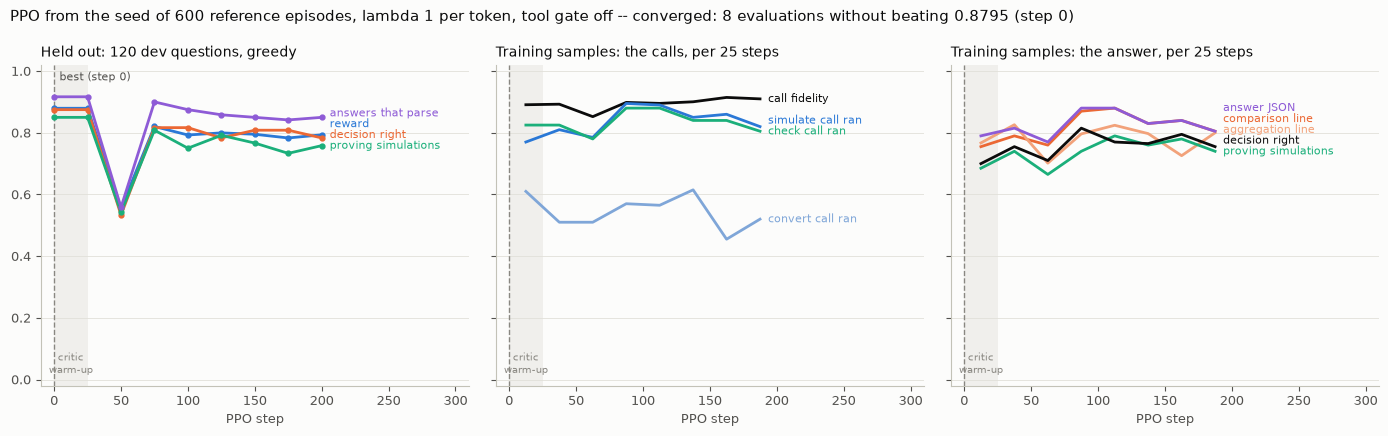


ppo-n600-open-lam1-s0: the sampled episodes by unit level, per 25 steps (every step's eight)
    steps level    n  conv/ep  anyConv  sim1Err  raw1st  simErr  calls/ep  answered  whole  reward  trunc
   0-24       0   84     0.60     0.20     0.02    0.00    0.06      4.23      0.98   0.86   0.919   0.00
   0-24       1   71     2.15     0.89     0.25    0.10    0.52      7.63      0.82   0.63   0.732   0.03
   0-24       2   45     3.53     1.00     0.71    0.60    0.88     10.96      0.44   0.20   0.340   0.16
   0-24     all  200     1.81     0.62     0.26    0.17    0.53      6.95      0.80   0.63   0.722   0.04
  25-49       0   88     0.32     0.06     0.01    0.00    0.00      4.06      1.00   0.91   0.928   0.00
  25-49       1   66     4.11     0.79     0.24    0.12    0.53      8.58      0.71   0.55   0.640   0.11
  25-49       2   46     8.28     0.98     0.46    0.28    0.76     14.78      0.61   0.50   0.629   0.13
  25-49     all  200     3.40     0.51     0.19    0.10   

 175-199      0   80     0.00     0.00     0.01    0.00    0.03      3.40      0.99   0.93   0.960   0.00
 175-199      1   73     2.38     0.82     0.30    0.22    0.46      7.70      0.86   0.75   0.787   0.04
 175-199      2   47     4.09     1.00     0.74    0.57    0.87     13.55      0.43   0.32   0.427   0.23
 175-199    all  200     1.83     0.54     0.29    0.21    0.56      7.36      0.81   0.72   0.772   0.07

ppo-n600-open-lam1-s0: the convert calls by unit level, per 25 steps
    steps level    n  conv/ep  sameUnit  repeated blocks1st  noCallTr  trunc convUsed
   0-24       0   84     0.60      0.20      0.15       2.5      0.00   0.00     0.56
   0-24       1   71     2.15      0.04      0.04       2.3      0.00   0.03     0.91
   0-24       2   45     3.53      0.07      0.33       3.0      0.00   0.16     0.95
   0-24     all  200     1.81      0.12      0.15       2.5      0.00   0.04     0.92
  25-49       0   88     0.32      0.30      0.00       2.9      0.00   0.00

 150-174      0   90     0.00      0.00      0.00       2.5      0.00   0.01      nan
 150-174      1   63     1.90      0.14      0.03       4.1      0.00   0.06     0.98
 150-174      2   47     4.47      0.21      0.17       6.3      0.00   0.26     0.90
 150-174    all  200     1.65      0.10      0.05       3.9      0.00   0.09     0.93
 175-199      0   80     0.00      0.00      0.00       2.3      0.00   0.00      nan
 175-199      1   73     2.38      0.03      0.12       4.3      0.00   0.04     0.96
 175-199      2   47     4.09      0.34      0.09       5.7      0.00   0.23     0.77
 175-199    all  200     1.83      0.09      0.07       3.9      0.00   0.07     0.86

levels 1 and 2 per 25 steps: ppo-n600-open-s0 (lambda 0.95 per token) | ppo-n600-open-lam1-s0 (lambda 1 per token)
    steps |       n conv/ep   sameU anyConv sim1Err     ans  reward   calls |       n conv/ep   sameU anyConv sim1Err     ans  reward   calls
   0-24   |      18    2.44    0.06    1.00    0.50   

 125-149  |       -       -       -       -       -       -       -       - |     132    4.15    0.56    0.95    0.57    0.75    0.69   10.20
 150-174  |       -       -       -       -       -       -       -       - |     110    3.00    0.17    0.85    0.48    0.73    0.68    9.45
 175-199  |       -       -       -       -       -       -       -       - |     120    3.05    0.15    0.89    0.47    0.69    0.65    9.99


In [14]:
R_LAM1 = load_run("ppo-n600-open-lam1-s0")
report_run(R_LAM1, "06_direction_and_compare_curves_lam1.png")
level_table(R_LAM1)
convert_table(R_LAM1)
paired_levels(R_COLLAPSED, R_LAM1)

### The unit of credit changed: the turn

`ppo-n600-open-turn-s0` is `ppo-n600-open-s0` with the turn as the unit of credit and nothing else changed: lambda 0.95 per turn instead of per
token; the same seed, the same random seed (the same train questions in the same order), the tool gate off, the answer-collapse rule at 0.5,
no no-regression gate, 200 steps; every step's eight episodes recorded. Its warm-up is the first run's warm-up byte for byte -- the same 25 x 8 episodes, the same per-step rewards -- so the two runs diverge only from the first actor update, and only through the advantage. A turn -- one assistant message: a block of
tool calls, or the answer -- is the action. Its reward is the sum of the credits that land on its tokens less their KL penalties; its value is
the critic's estimate at its first token, the hidden state before the turn; the GAE recursion runs over the turns; every token of a turn
carries its turn's advantage. What that changes: the first simulate call's fidelity credit and the convert-or-simulate choice sit in the same
turn, so the credit reaches the choice at weight 1, where lambda 0.95 per token gave it 0.95^431, 3e-10, across the median first turn; the answer's decision credit two turns later weighs 0.90. What it
does not change: inside a turn no token is told from another, as under lambda 1 -- a needless convert call in a turn that was right earns the
turn's credit. The three criteria written before the lambda-1 run are read on this run as well.

**The run ended at step 150 (critic gate, value_ev not above the position clock at two evaluations).** The evaluations on the 120 dev questions started at 0.8795 (decisions 0.875) and no later evaluation beat it. In the training samples, from the warm-up steps to the actor's steps 25-150: call fidelity 0.891 to 0.610, proving simulations 0.685 to 0.459, decisions 0.700 to 0.453, answers 0.820 to 0.896; comparison lines 0.755 to 0.501, aggregation lines 0.767 to 0.393, check calls that ran 0.825 to 0.522. The activation of each label over the run is the figure. The calls, from the warm-up to the last 25 steps: 7.0 to 0.0 per episode, 0.36 to 0.00 of them errored, 1.2 to 0.0 exact repeats of an earlier call per episode, 0.04 to 0.00 of the episodes cut at the token budget. Sampled at T=1 in training, the actor's steps 25-150 scored 0.477 against the warm-up's 0.722 (KL to the seed 0.7371 per token); greedy on the 120 dev questions, the evaluations after the warm-up scored 0.870, 0.813, 0.568, 0.000, 0.000 against 0.879 at the start. The best evaluation is step 0, the seed itself, so the seed's held-out numbers are this run's result.

**What it did.** For the first 50 actor steps the credit did what it was changed to do. On the level-1 and level-2 questions, from the warm-up to steps 50-74: the share of episodes with a convert call 0.93 to 0.98, the first simulate call erring 0.43 to 0.31, answered 0.67 to 0.76, whole answers right 0.47 to 0.58, the episodes cut at the token budget 0.08 to 0.05; over all the questions the sampled reward 0.722 to 0.804, whole answers right 0.63 to 0.70 (the seed's run with the token as the unit over the same steps: the share converting 0.84, the first simulate call erring 0.63, whole answers right 0.26). What it did not touch: an erroring simulate call retried rather than fixed -- 30 of the 110 level-1-2 episodes over those steps made three or more erroring simulate calls, the longest 20 in a row. The greedy evaluations at steps 50, 75 scored 0.870, 0.813 against 0.879 at the start, the share of calls that errored 0.36 to 0.26 and the episodes cut at the budget 0.04 to 0.01.

Then the policy ran away. KL to the seed per token: 0.0057 over steps 50-74, 0.0257 over 75-99, 3.16 over the last 25; the sampled reward 0.804, 0.613, 0.000. Over steps 75-99 whole answers right fell to 0.48 (0.70 over 50-74), decisions right to 0.57 (0.81); calls per episode 6.5 over steps 50-74 and 0.0 over the last 25, no call at all, the answer written in 14 tokens. The critic's explained variance, 0.38 over steps 50-74, was -1.37 over the last 25; the evaluations after step 75: 0.568, 0.000, 0.000. The run ended at step 150: critic gate.

Why it ran. A turn's advantage is its return less the critic's value at the turn's start, carried by every token of the turn: per token its spread over actor steps 25-74 was 0.24, against 0.05 under lambda 0.95 per token and 0.27 under lambda 1 -- 5 times the gradient per step at the same actor learning rate. The critic it leans on fits the turns' returns less well than the token critic fits its own targets (explained variance 0.38 against 0.63 over the same steps). When the episodes changed the critic lagged (explained variance 0.25 over steps 75-99, -1.37 over the last 25) and a step that large carried the actor past recovery. The unit was changed and the step was not; the fourth run below changes only the step.

**The criteria.** (1) 0.93 of the level-1-2 episodes converted in the warm-up, 0.00 over the last 25 steps (convert calls per episode 2.69 to 0.00; the first simulate call erroring 0.43 to 0.00): not met. Over the last 25 steps the episodes made no call at all. (2) best step 0, 0.879 against 0.879 at the start: not met. (3) the best is step 0, nothing of the run's own to hold out: not met. None of the three met. By the method's test, the seed is not activated by this run either.

== ppo-n600-open-turn-s0: lambda 0.95 per turn, tool gate off
{'stopped_at': 150, 'reason': 'critic gate: value_ev not above the position clock at two evaluations', 'best_step': 0, 'best_reward': 0.8794788779709415}

 step  reward  decision  proving  answers  violations  values  errored  critic - clock
    0   0.879     0.875    0.850    0.917       0.894   0.864    0.358               -
   25   0.879     0.875    0.850    0.917       0.894   0.864    0.358          +0.298
   50   0.870     0.875    0.850    0.933       0.836   0.859    0.264          +0.286
   75   0.813     0.833    0.792    0.917       0.808   0.772    0.264          +0.365
  100   0.568     0.508    0.533    0.733       0.603   0.500    0.339          +0.262
  125   0.000     0.000    0.000    0.000       0.000   0.000    0.000          -0.320
  150   0.000     0.000    0.000    0.000       0.000   0.000    0.000          -0.796

    steps  reward  fidelity  sim ran  convert  check  proving  compare  aggreg.  answe

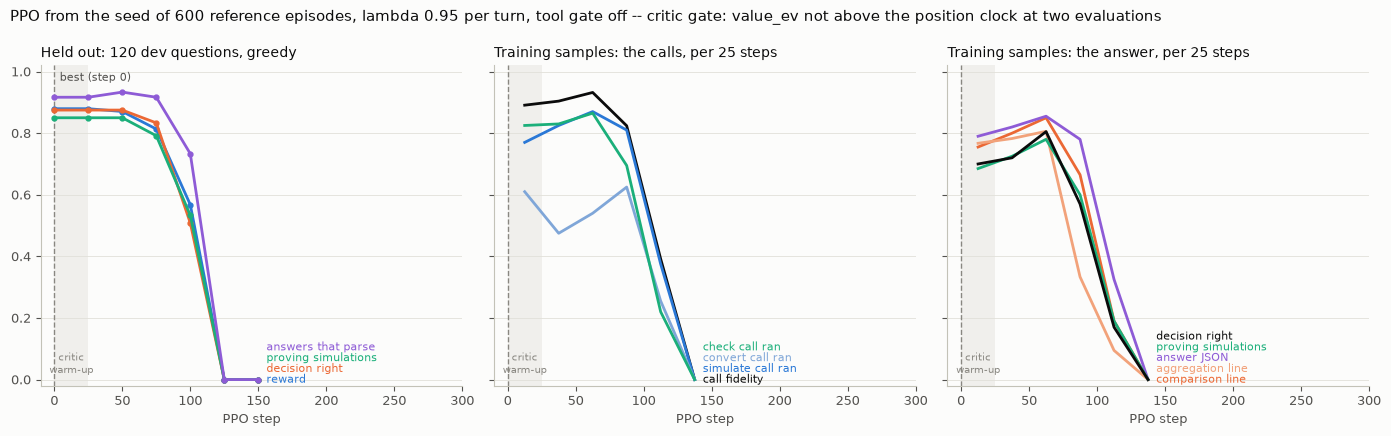


ppo-n600-open-turn-s0: the sampled episodes by unit level, per 25 steps (every step's eight)
    steps level    n  conv/ep  anyConv  sim1Err  raw1st  simErr  calls/ep  answered  whole  reward  trunc
   0-24       0   84     0.60     0.20     0.02    0.00    0.06      4.23      0.98   0.86   0.919   0.00
   0-24       1   71     2.15     0.89     0.25    0.10    0.52      7.63      0.82   0.63   0.732   0.03
   0-24       2   45     3.53     1.00     0.71    0.60    0.88     10.96      0.44   0.20   0.340   0.16
   0-24     all  200     1.81     0.62     0.26    0.17    0.53      6.95      0.80   0.63   0.722   0.04
  25-49       0   88     0.10     0.03     0.00    0.00    0.00      3.88      0.98   0.85   0.893   0.00
  25-49       1   66     2.21     0.74     0.32    0.14    0.62      7.56      0.76   0.61   0.686   0.03
  25-49       2   46     5.17     0.98     0.48    0.30    0.81     11.65      0.61   0.46   0.553   0.20
  25-49     all  200     1.97     0.48     0.21    0.12   

 125-149      0   68     0.00      0.00      0.00       1.0      0.00   0.00      nan
 125-149      1   76     0.00      0.00      0.00       1.0      0.00   0.00      nan
 125-149      2   56     0.00      0.00      0.00       1.0      0.00   0.00      nan
 125-149    all  200     0.00      0.00      0.00       1.0      0.00   0.00      nan

levels 1 and 2 per 25 steps: ppo-n600-open-s0 (lambda 0.95 per token) | ppo-n600-open-turn-s0 (lambda 0.95 per turn)
    steps |       n conv/ep   sameU anyConv sim1Err     ans  reward   calls |       n conv/ep   sameU anyConv sim1Err     ans  reward   calls
   0-24   |      18    2.44    0.06    1.00    0.50    0.67    0.55   10.17 |     116    2.69    0.05    0.93    0.43    0.67    0.58    8.92
  25-49   |      20    2.40    0.00    1.00    0.25    0.80    0.71    6.70 |     112    3.43    0.30    0.84    0.38    0.70    0.63    9.24
  50-74   |      19    1.79    0.00    0.84    0.63    0.42    0.41    9.89 |     110    3.45    0.25    0.98   

In [15]:
R_TURN = load_run("ppo-n600-open-turn-s0")
report_run(R_TURN, "06_direction_and_compare_curves_turn.png")
level_table(R_TURN)
convert_table(R_TURN)
paired_levels(R_COLLAPSED, R_TURN)
print("\nthe critic at the first token, by unit level:")
critic_by_level(R_TURN)

### The turn at a fifth of the actor step

`ppo-n600-open-turn-lr2e6-s0` is `ppo-n600-open-turn-s0` with the actor's learning rate at 2e-6 instead of 1e-5 and
nothing else changed: lambda 0.95 per turn, the same seed and random seed, the tool gate off, the answer-collapse rule at 0.5, no
no-regression gate, 200 steps, every step's eight episodes recorded. Its warm-up is the third run's byte for byte, so the two diverge only from the first actor update, and only through the size of it. In the third run a turn's advantage spread 0.24 per token over actor steps 25-74 against 0.05 in the seed's run with the token as the unit, so the same learning rate moved the policy about 5 times as far per step; a fifth of the step puts the turn's credit at roughly the token run's pace. The three criteria are read on
this run as well.

**The run ended at step 200 (converged, 8 evaluations without beating 0.8795, step 0).** The evaluations on the 120 dev questions started at 0.8795 (decisions 0.875) and no later evaluation beat it. In the training samples, from the warm-up steps to the actor's steps 25-200: call fidelity 0.891 to 0.903, proving simulations 0.685 to 0.725, decisions 0.700 to 0.749, answers 0.820 to 0.817; comparison lines 0.755 to 0.797, aggregation lines 0.767 to 0.725, check calls that ran 0.825 to 0.814. The activation of each label over the run is the figure. The calls, from the warm-up to the last 25 steps: 7.0 to 6.5 per episode, 0.36 to 0.32 of them errored, 1.2 to 1.0 exact repeats of an earlier call per episode, 0.04 to 0.01 of the episodes cut at the token budget. Sampled at T=1 in training, the actor's steps 25-200 scored 0.762 against the warm-up's 0.722 (KL to the seed 0.0015 per token); greedy on the 120 dev questions, the evaluations after the warm-up scored 0.809, 0.826, 0.829, 0.809, 0.848, 0.845, 0.847 against 0.879 at the start. The best evaluation is step 0, the seed itself, so the seed's held-out numbers are this run's result.

**What it did.** Its best window was steps 150-174, 150 actor steps in. On the level-1 and level-2 questions, from the warm-up to steps 150-174: the share of episodes with a convert call 0.93 to 0.87, the first simulate call erring 0.43 to 0.32, answered 0.67 to 0.70, whole answers right 0.47 to 0.56, the episodes cut at the token budget 0.08 to 0.04; over all the questions the sampled reward 0.722 to 0.810, whole answers right 0.63 to 0.73. What it did not touch: an erroring simulate call retried rather than fixed -- 34 of the 108 level-1-2 episodes over those steps made three or more erroring simulate calls, the longest 20 in a row. The greedy evaluations at steps 50, 75, 100, 125, 150, 175 scored 0.809, 0.826, 0.829, 0.809, 0.848, 0.845 against 0.879 at the start, the share of calls that errored unchanged at 0.36 and the episodes cut at the budget 0.04 to 0.03.

Over the last 25 steps (175-199): the share converting 0.91, the first simulate call erring 0.40, whole answers right 0.57 on the level-1-2 questions and 0.71 on all (0.63 in the warm-up), the sampled reward 0.783; KL to the seed 0.0023 per token, the critic's explained variance 0.30. The evaluations after step 175: 0.847 against 0.879 at the start; the best, step 0 at 0.879.

**The step.** Over actor steps 25-49, KL to the seed 0.0002 per token against 0.0024 in the run at the full step, the advantage's spread per token 0.23 against 0.25: the same credit, a fifth of the step, the KL 15 times smaller. The run at the full step reached its best window, steps 50-74, at reward 0.804; this run reached 0.810 at steps 150-174, and did not run away.

**The criteria.** (1) 0.93 of the level-1-2 episodes converted in the warm-up, 0.91 over the last 25 steps (convert calls per episode 2.69 to 2.75; the first simulate call erroring 0.43 to 0.40): not met. (2) best step 0, 0.879 against 0.879 at the start: not met. (3) the best is step 0, nothing of the run's own to hold out: not met. None of the three met. By the method's test, the seed is not activated by this run either.

== ppo-n600-open-turn-lr2e6-s0: lambda 0.95 per turn, actor lr 2e-6, tool gate off
{'stopped_at': 200, 'reason': 'converged: 8 evaluations without beating 0.8795 (step 0)', 'best_step': 0, 'best_reward': 0.8794788779709415}

 step  reward  decision  proving  answers  violations  values  errored  critic - clock
    0   0.879     0.875    0.850    0.917       0.894   0.864    0.358               -
   25   0.879     0.875    0.850    0.917       0.894   0.864    0.358          +0.298
   50   0.809     0.783    0.767    0.808       0.805   0.767    0.541          +0.352
   75   0.826     0.817    0.783    0.867       0.820   0.791    0.444          +0.285
  100   0.829     0.808    0.792    0.850       0.829   0.772    0.482          +0.321
  125   0.809     0.792    0.767    0.825       0.780   0.757    0.533          +0.373
  150   0.848     0.833    0.817    0.858       0.821   0.811    0.462          +0.391
  175   0.845     0.833    0.817    0.883       0.809   0.811    0.356         

   0-24        6.95     0.36                  1.18       4.3    1081      0.045       0.255
  25-49        6.49     0.34                  1.01       4.2    1020      0.050       0.230
  50-74        6.48     0.34                  1.06       4.3     993      0.025       0.305
  75-99        6.04     0.29                  0.70       4.2     894      0.015       0.235
 100-124       6.50     0.32                  0.84       4.3     991      0.025       0.280
 125-149       6.64     0.33                  0.72       4.5     989      0.030       0.320
 150-174       6.12     0.31                  0.87       4.1     931      0.020       0.295
 175-199       6.49     0.32                  0.97       4.3     979      0.010       0.285

actor steps where the critic explains the return better than the position clock: 143/175


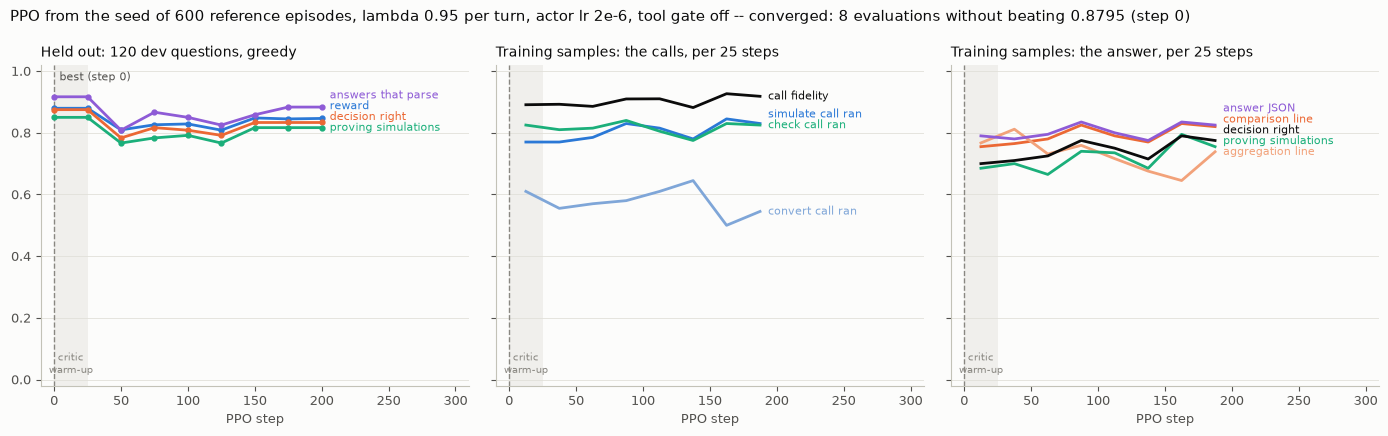


ppo-n600-open-turn-lr2e6-s0: the sampled episodes by unit level, per 25 steps (every step's eight)
    steps level    n  conv/ep  anyConv  sim1Err  raw1st  simErr  calls/ep  answered  whole  reward  trunc
   0-24       0   84     0.60     0.20     0.02    0.00    0.06      4.23      0.98   0.86   0.919   0.00
   0-24       1   71     2.15     0.89     0.25    0.10    0.52      7.63      0.82   0.63   0.732   0.03
   0-24       2   45     3.53     1.00     0.71    0.60    0.88     10.96      0.44   0.20   0.340   0.16
   0-24     all  200     1.81     0.62     0.26    0.17    0.53      6.95      0.80   0.63   0.722   0.04
  25-49       0   88     0.07     0.06     0.02    0.00    0.04      3.93      0.98   0.91   0.925   0.01
  25-49       1   66     1.82     0.94     0.30    0.23    0.50      6.61      0.82   0.68   0.752   0.03
  25-49       2   46     3.89     0.98     0.70    0.57    0.89     11.22      0.37   0.20   0.352   0.15
  25-49     all  200     1.52     0.56     0.27    0

  25-49       0   88     0.07      0.03      0.00       2.7      0.00   0.01     0.50
  25-49       1   66     1.82      0.11      0.05       1.9      0.00   0.03     0.99
  25-49       2   46     3.89      0.20      0.07       3.7      0.00   0.15     0.97
  25-49     all  200     1.52      0.10      0.03       2.7      0.00   0.05     0.97
  50-74       0   90     0.13      0.08      0.00       2.5      0.00   0.00     0.67
  50-74       1   61     1.89      0.07      0.13       1.9      0.00   0.05     0.97
  50-74       2   49     3.92      0.16      0.18       3.4      0.00   0.04     0.94
  50-74     all  200     1.59      0.10      0.09       2.5      0.00   0.03     0.95
  75-99       0   74     0.01      0.01      0.00       2.5      0.00   0.00      nan
  75-99       1   71     1.92      0.13      0.13       1.9      0.00   0.01     0.99
  75-99       2   55     3.33      0.18      0.07       2.9      0.00   0.04     0.95
  75-99     all  200     1.60      0.10      0.07     

  25-49   |     112    3.43    0.30    0.84    0.38    0.70    0.63    9.24 |     112    2.67    0.14    0.96    0.46    0.63    0.59    8.50
  50-74   |     110    3.45    0.25    0.98    0.31    0.76    0.70    8.78 |     110    2.79    0.11    0.97    0.45    0.64    0.59    8.77
  75-99   |     126    2.21    0.08    0.90    0.27    0.75    0.54    5.21 |     126    2.53    0.15    0.91    0.37    0.74    0.67    7.52
 100-124  |     121    0.77    0.02    0.42    0.19    0.34    0.15    1.86 |     121    2.52    0.09    0.94    0.40    0.69    0.65    8.03
 125-149  |     132    0.00    0.00    0.00    0.00    0.00    0.00    0.00 |     132    2.86    0.13    0.97    0.40    0.68    0.64    8.01
 150-174  |       -       -       -       -       -       -       -       - |     110    2.67    0.12    0.87    0.32    0.70    0.68    8.19
 175-199  |       -       -       -       -       -       -       -       - |     120    2.75    0.05    0.91    0.40    0.72    0.66    8.57

the c

  steps 175-199 of the window; 200 sampled episodes aligned, 0 steps not
  level    n  V at token 0   return   reward
      0   80         0.769    0.949    0.965
      1   73         0.725    0.765    0.793
      2   47         0.645    0.434    0.459


In [16]:
R_TURN_SLOW = load_run("ppo-n600-open-turn-lr2e6-s0")
report_run(R_TURN_SLOW, "06_direction_and_compare_curves_turn_lr2e6.png")
level_table(R_TURN_SLOW)
convert_table(R_TURN_SLOW)
paired_levels(R_TURN, R_TURN_SLOW)
print("\nthe critic at the first token, by unit level:")
critic_by_level(R_TURN_SLOW)

### The next dose: 1200 episodes, lambda 0.95

The method's own answer to a run that could not activate the seed is a little more SFT: the next dose on the ladder, 1200 episodes --
every reference episode, and a seed far past barely working (dev decisions 0.808, reward 0.840 sampled at T=1).
The run has the configuration of the seed's first run, lambda 0.95, from that seed; its value head is warm-started at 0.840.

**The run ended at step 200 (converged, 8 evaluations without beating 0.9467, step 0).** The evaluations on the 120 dev questions started at 0.9467 (decisions 0.950) and no later evaluation beat it. In the training samples, from the warm-up steps to the actor's steps 25-200: call fidelity 0.982 to 0.941, proving simulations 0.935 to 0.831, decisions 0.845 to 0.790, answers 0.965 to 0.878; comparison lines 0.975 to 0.879, aggregation lines 1.000 to 0.762, check calls that ran 0.975 to 0.893. The activation of each label over the run is the figure. The calls, from the warm-up to the last 25 steps: 5.5 to 5.8 per episode, 0.03 to 0.25 of them errored, 0.1 to 0.7 exact repeats of an earlier call per episode, 0.00 to 0.07 of the episodes cut at the token budget. Sampled at T=1 in training, the actor's steps 25-200 scored 0.811 against the warm-up's 0.877 (KL to the seed 0.0035 per token); greedy on the 120 dev questions, the evaluations after the warm-up scored 0.926, 0.870, 0.898, 0.906, 0.900, 0.868, 0.788 against 0.947 at the start. The best evaluation is step 0, the seed itself, so the seed's held-out numbers are this run's result.

**What it did.** On the level-1 and level-2 questions the run moved the way the seed's run at this lambda did: the share of episodes with a convert call 1.00 in the warm-up and 0.91 over the last 25 steps (convert calls per episode 3.61 to 2.39), and the first simulate call erred 0.00 in the warm-up and 0.45 over steps 150-174, 0.36 of the episodes passing a number the question states in another unit -- a temperature in Fahrenheit, a permeability in LMH, a pressure in kPa -- to the simulator unconverted (0.06 in the warm-up), 1.00 of those episodes having converted another of the question's inputs; over the last 25 steps the first simulate call erred 0.22 and 0.13 of the episodes passed a number unconverted. The erroring call was retried rather than fixed: over steps 150-174, 11 of the 22 level-1-2 episodes made three or more erroring simulate calls, the longest 20 in a row, 0.64 of those episodes ending at the token budget. In the greedy evaluations the share of calls that errored went 0.12 at step 0 to 0.47 at step 200, answers found 0.975 to 0.800. Read with the diagnosis of the seed's run: the same discount between a skipped conversion and the simulate error that is its bad news.

**Read by the lambda-1 run's three criteria.** (1) 1.00 of the level-1-2 episodes converted in the warm-up, 0.91 over the last 25 steps (convert calls per episode 3.61 to 2.39; the first simulate call erroring 0.00 to 0.22): not met. (2) best step 0, 0.947 against 0.947 at the start: not met. (3) the best is step 0, nothing of the run's own to hold out: not met. None of the three met. By the method's test, PPO did not activate this dose.

== ppo-n1200-open-s0: lambda 0.95 per token, tool gate off
{'stopped_at': 200, 'reason': 'converged: 8 evaluations without beating 0.9467 (step 0)', 'best_step': 0, 'best_reward': 0.9467451656588561}

 step  reward  decision  proving  answers  violations  values  errored  critic - clock
    0   0.947     0.950    0.967    0.975       0.976   0.947    0.120               -
   25   0.947     0.950    0.967    0.975       0.976   0.947    0.120          +0.149
   50   0.926     0.925    0.958    0.975       0.853   0.927    0.144          +0.186
   75   0.870     0.825    0.925    0.917       0.890   0.903    0.316          +0.109
  100   0.898     0.900    0.892    0.908       0.912   0.879    0.341          +0.143
  125   0.906     0.900    0.917    0.925       0.860   0.898    0.163          +0.136
  150   0.900     0.900    0.892    0.908       0.906   0.893    0.324          +0.152
  175   0.868     0.850    0.858    0.883       0.845   0.845    0.341          +0.154
  200   0.788   

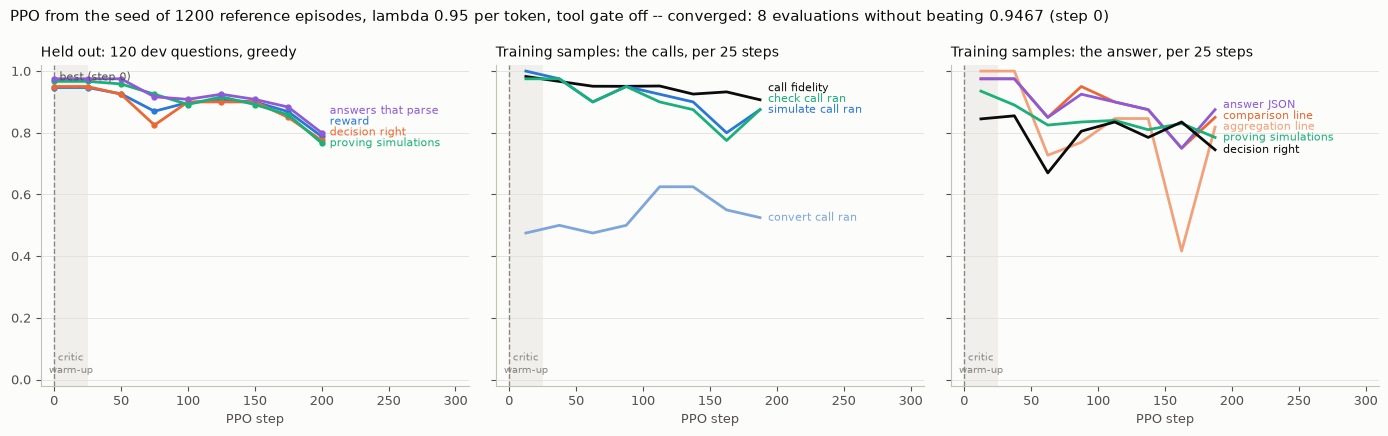


ppo-n1200-open-s0: the sampled episodes by unit level, per 25 steps (every 5th step's eight)
    steps level    n  conv/ep  anyConv  sim1Err  raw1st  simErr  calls/ep  answered  whole  reward  trunc
   0-24       0   22     0.09     0.05     0.00    0.00    0.00      3.41      1.00   0.86   0.931   0.00
   0-24       1    9     1.56     1.00     0.00    0.00    0.00      5.89      1.00   1.00   0.976   0.00
   0-24       2    9     5.67     1.00     0.00    0.11    0.14     10.44      0.89   0.67   0.735   0.00
   0-24     all   40     1.68     0.47     0.00    0.03    0.04      5.55      0.97   0.85   0.897   0.00
  25-49       0   20     0.00     0.00     0.00    0.00    0.00      3.35      1.00   0.90   0.961   0.00
  25-49       1   14     2.07     1.00     0.00    0.00    0.03      5.64      1.00   0.79   0.867   0.00
  25-49       2    6     4.67     1.00     0.17    0.00    0.71      9.00      0.83   0.33   0.842   0.17
  25-49     all   40     1.43     0.50     0.03    0.00   

In [17]:
R_NEXT = load_run("ppo-n1200-open-s0")
report_run(R_NEXT, "06_direction_and_compare_curves_n1200.png")
level_table(R_NEXT)

## Held out

The seed alone and, when the run exists, PPO's best checkpoint: greedy, answers stopped at their
closing brace, on test and on holdout_shift; then the item-by-item decomposition, with the operators
per limited field on holdout_shift, for 05's and this notebook's policies.

== test (240 questions): 05 seed | 05 PPO | 06 seed 1200 | 06 seed
                                       reward                       decision right                    whole answer                     proving sims          
   all                      0.916   0.920   0.925   0.816    0.908   0.908   0.917   0.796    0.817   0.846   0.879   0.775    0.983   0.988   0.942   0.775
   ro_check                 0.976   0.977   0.912   0.813    0.975   0.975   0.900   0.800    0.850   0.925   0.775   0.775    1.000   0.975   0.925   0.775
   ro_membrane              0.945   0.947   0.950   0.816    0.950   0.950   0.950   0.775    0.925   0.925   0.925   0.775    0.975   0.950   0.975   0.775
   ro_scan_area             0.818   0.793   0.876   0.662    0.750   0.725   0.850   0.600    0.725   0.700   0.825   0.575    1.000   1.000   0.925   0.600
   ro_scan_pressure         0.887   0.919   0.879   0.769    0.925   0.925   0.875   0.750    0.825   0.900   0.875   0.750    0.950   1.000   0.92

== holdout_shift (120 questions): 05 seed | 05 PPO | 06 seed 1200 | 06 seed
                                       reward                       decision right                    whole answer                     proving sims          
   all                      0.699   0.739   0.880   0.802    0.592   0.650   0.867   0.767    0.450   0.517   0.850   0.717    0.892   0.900   0.867   0.775
   ro_check                 0.871   0.874   0.996   0.954    0.800   0.800   1.000   0.950    0.500   0.500   1.000   0.950    1.000   1.000   1.000   0.950
   ro_membrane              0.703   0.824   0.881   0.720    0.650   0.850   0.900   0.650    0.550   0.750   0.850   0.650    0.700   0.800   0.850   0.700
   ro_scan_area             0.600   0.610   0.754   0.614    0.450   0.500   0.700   0.550    0.400   0.450   0.700   0.550    0.950   0.850   0.750   0.450
   ro_scan_pressure         0.612   0.668   0.788   0.743    0.500   0.550   0.750   0.700    0.450   0.550   0.750   0.700    0.850   0.8

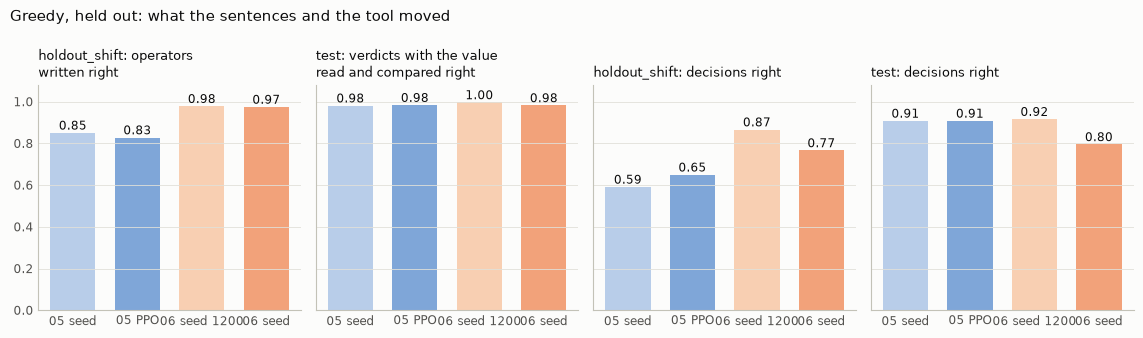

In [18]:
def mcnemar(b, c):
    n = b + c
    return 1.0 if n == 0 else min(1.0, 2 * sum(math.comb(n, i) for i in range(min(b, c) + 1)) / 2 ** n)


def exact(ep):
    """The whole answer right: it parses, the decision, the violations and every number are right."""
    s, c = ep["score"], ep["score"]["components"]
    return bool(s["decision_correct"]) and c.get("format", 0) == 1 and c.get("violations", 1) == 1 and c.get("values", 1) == 1


seed_dir = RUNS / SEED06 / CKPT06
policies = [("05 seed", RUNS05 / "label-seed-pc2" / "epoch3"), ("05 PPO", RUNS05 / "ppo-s0" / "best")]
for n in sorted(int(d.name.split("-n")[1]) for d in RUNS.glob("label-seed-n*") if (d / "epoch1" / "test-T0-stop.episodes.jsonl").exists()):
    if RUNS / f"label-seed-n{n}" / "epoch1" != seed_dir:   # the other alive doses held out (the next dose among them)
        policies.append((f"06 seed {n}", RUNS / f"label-seed-n{n}" / "epoch1"))
policies.append(("06 seed", seed_dir))
bests = [(label, RUNS / run / "best") for label, run in BESTS if (RUNS / run / "best" / "test-T0-stop.episodes.jsonl").exists()]   # each PPO run's best checkpoint, when it is not step 0
policies += bests
ctrl_dir = RUNS / "label-seed-pc2-nocompare" / "epoch3"   # the control: the same bank, 05's episode, no check tool
if (ctrl_dir / "test-T0-stop.episodes.jsonl").exists():
    policies.insert([p[0] for p in policies].index("06 seed"), ("06 sentences", ctrl_dir))
for split in ("test", "holdout_shift"):
    cs = cases_of(split)
    reps = {name: nw.episode_report(d / f"{split}-T0-stop.episodes.jsonl", split) for name, d in policies}
    ex = {}
    for name, d in policies:
        ex[name] = collections.defaultdict(lambda: [0, 0])
        for r in rows_of(d / f"{split}-T0-stop.episodes.jsonl"):
            c = cs[r["id"]]
            for key in ("all:", f"family:{c['family']}", f"level:{c['level']}"):
                ex[name][key][0] += exact(r)
                ex[name][key][1] += 1
    names = [p[0] for p in policies]
    print(f"== {split} ({reps[names[0]]['all:']['n']} questions): " + " | ".join(names))
    print(f"   {'':22} {'reward':^{8 * len(names)}} {'decision right':^{8 * len(names)}} {'whole answer':^{8 * len(names)}} {'proving sims':^{8 * len(names)}}")
    for key in ["all:"] + [k for k in reps[names[0]] if k != "all:"]:
        label = "all" if key == "all:" else key.replace("family:", "").replace("level:", "unit level ")
        cols = []
        for metric_ in ("reward", "decision_correct", "whole", "evidence"):
            if metric_ == "whole":
                cols.append(" ".join(f"{ex[n][key][0] / max(1, ex[n][key][1]):>7.3f}" for n in names))
            else:
                cols.append(" ".join(f"{reps[n][key][metric_]:>7.3f}" for n in names))
        print(f"   {label:22} " + "  ".join(cols))
    s_rows = {r["id"]: r for r in rows_of(seed_dir / f"{split}-T0-stop.episodes.jsonl")}
    o_rows = {r["id"]: r for r in rows_of(RUNS05 / "label-seed-pc2" / "epoch3" / f"{split}-T0-stop.episodes.jsonl")}
    only_6 = sum(s_rows[i]["score"]["decision_correct"] and not o_rows[i]["score"]["decision_correct"] for i in s_rows)
    only_5 = sum(o_rows[i]["score"]["decision_correct"] and not s_rows[i]["score"]["decision_correct"] for i in s_rows)
    print(f"   06's seed against 05's: decisions right only under 06 {only_6}, only under 05 {only_5}: McNemar p = {mcnemar(only_6, only_5):.2g}")
    if ("06 sentences", ctrl_dir) in policies:
        c_rows = {r["id"]: r for r in rows_of(ctrl_dir / f"{split}-T0-stop.episodes.jsonl")}
        only_t = sum(s_rows[i]["score"]["decision_correct"] and not c_rows[i]["score"]["decision_correct"] for i in s_rows)
        only_c = sum(c_rows[i]["score"]["decision_correct"] and not s_rows[i]["score"]["decision_correct"] for i in s_rows)
        print(f"   06's seed against the sentences-only seed: right only with the check tool {only_t}, only without it {only_c}: McNemar p = {mcnemar(only_t, only_c):.2g}")
    for label, best_dir in bests:
        b_rows = {r["id"]: r for r in rows_of(best_dir / f"{split}-T0-stop.episodes.jsonl")}
        own = RUNS / f"label-seed-n{re.match(r'ppo-n(\\d+)', best_dir.parent.name).group(1)}" / "epoch1"   # the seed that run started from
        o_rows = {r["id"]: r for r in rows_of(own / f"{split}-T0-stop.episodes.jsonl")}
        only_b = sum(b_rows[i]["score"]["decision_correct"] and not o_rows[i]["score"]["decision_correct"] for i in b_rows)
        only_s = sum(o_rows[i]["score"]["decision_correct"] and not b_rows[i]["score"]["decision_correct"] for i in b_rows)
        print(f"   {label} against the seed it started from ({own.parent.name}): right only under PPO {only_b}, only under the seed {only_s}: McNemar p = {mcnemar(only_b, only_s):.2f}")
    print()
for label, best_dir in bests:
    if (best_dir / "dev-T0-stop.episodes.jsonl").exists():
        dev_all = nw.episode_report(best_dir / "dev-T0-stop.episodes.jsonl", "dev")["all:"]
        ending = json.loads((best_dir.parent / "ending.json").read_text())
        print(f"{label}, best checkpoint on all 240 dev questions: reward {dev_all['reward']:.3f} (chosen at {ending['best_reward']:.3f} on 120 of them)\n")

d06 = {}
for name, d in [p for p in policies if p[0] in ("06 sentences", "06 seed") or p in bests]:
    for split in ("test", "holdout_shift"):
        d06[(name, split)] = show(f"{name}, {split}", d / f"{split}-T0-stop.episodes.jsonl", cases_of(split), operators=(split == "holdout_shift"))
        print()

# Figure: the policies on the four things this notebook set out to move.
labels = [p[0] for p in policies]
def dec_of(name, split):
    return d05[f"05's seed, {split}"] if name == "05 seed" else d06[(name, split)] if (name, split) in d06 else decompose(dict(policies)[name] / f"{split}-T0-stop.episodes.jsonl", cases_of(split))
def ops_right(name):
    o = dec_of(name, "holdout_shift")[2]
    return 1 - sum(v[0] for v in o.values()) / max(1, sum(v[1] for v in o.values()))
def comparisons_right(name):
    c_ = dec_of(name, "test")[0]
    return 1 - (c_.get("verdict wrong: comparison", 0) + c_.get("verdict wrong: value wrong", 0)) / max(1, c_.get("items", 1))
def decisions(name, split):
    r = rows_of(dict(policies)[name] / f"{split}-T0-stop.episodes.jsonl")
    return st.mean(e["score"]["decision_correct"] for e in r)
panels = [("holdout_shift: operators\nwritten right", [ops_right(n) for n in labels]),
          ("test: verdicts with the value\nread and compared right", [comparisons_right(n) for n in labels]),
          ("holdout_shift: decisions right", [decisions(n, "holdout_shift") for n in labels]),
          ("test: decisions right", [decisions(n, "test") for n in labels])]
fig, axes = plt.subplots(1, 4, figsize=(11.5 if len(labels) < 5 else 13, 3.4), sharey=True, facecolor="#fcfcfb")
colors = {"05 seed": "#b8cde9", "05 PPO": "#7fa6d8", "06 sentences": "#f7cdb5", "06 seed": "#f2a27a"}
colors = [colors.get(n, "#eb6834" if n.startswith("06 PPO") else "#f8cfb2") for n in labels]   # PPO bests: the dark orange; the other doses' seeds: a lighter one
for ax, (title, ys) in zip(axes, panels):
    ax.set_facecolor("#fcfcfb")
    ax.bar(range(len(labels)), ys, color=colors, width=0.7)
    for i, y in enumerate(ys):
        ax.text(i, y + 0.015, f"{y:.2f}", ha="center", fontsize=8.5, color="#0b0b0b")
    ax.set_xticks(range(len(labels)), labels, fontsize=8.5, color="#52514e")
    ax.set_title(title, fontsize=9.5, color="#0b0b0b", loc="left")
    ax.set_ylim(0, 1.08)
    ax.grid(axis="y", color="#e1e0d9", lw=0.6)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", labelsize=8.5, length=0)
fig.suptitle("Greedy, held out: what the sentences and the tool moved", fontsize=10.5, color="#0b0b0b", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(HERE / "06_direction_and_compare_errors.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

## The slow turn run, sampled on dev

Every evaluation above is greedy on 120 dev questions; every training-sample number is T=1 on train questions.
For the fourth run from the seed (the turn as the unit, actor lr 2e-6) the two disagree: its sampled reward rose
from 0.722 in the warm-up to 0.810 over steps 150-174 (0.783 over the last 25), while its greedy evaluations
stayed between 0.809 and 0.848 against 0.879 at the start. They measure different things. Greedy writes the
policy's single most likely path; T=1 averages over everything the policy might write. The seed's two differ by
0.18 on dev (greedy 0.879 on the 120 questions, T=1 0.702 on all 240 sampled twice): much of its probability sits
on paths greedy never takes, and PPO, which maximises the reward of sampled episodes, can take those paths away
without changing the greedy one.

So two of the run's checkpoints are probed the way the seed was: all 240 dev questions, twice each at T=1,
answers stopped at their closing brace. Step 175 closes the run's best sampled window; step 200 is its last
checkpoint, chosen by nothing. Set before the probes ran: a difference from the seed counts when the 95%
interval of the per-question paired difference excludes zero.

In [19]:
TURN_SLOW = "ppo-n600-open-turn-lr2e6-s0"
T1_PROBES = [("the seed (step 0)", RUNS / SEED06 / CKPT06), ("step 175", RUNS / TURN_SLOW / "step175"),
             ("step 200", RUNS / TURN_SLOW / "step200")]
T1_PROBES = [(n, d) for n, d in T1_PROBES if (d / "dev-T1-x2-stop.json").exists()]
dev_cases = cases_of("dev")
evals_slow = {r["step"]: r for r in rows_of(RUNS / TURN_SLOW / "eval.jsonl")}


def by_question(rows, f):
    """Each dev question's mean of f over its samples."""
    q = collections.defaultdict(list)
    for r in rows:
        q[r["id"]].append(f(r))
    return {k: sum(v) / len(v) for k, v in q.items()}


t1 = {name: rows_of(d / "dev-T1-x2-stop.episodes.jsonl") for name, d in T1_PROBES}
t1_overall = {name: json.loads((d / "dev-T1-x2-stop.json").read_text())["overall"] for name, d in T1_PROBES}
cols = [("reward", lambda r: r["score"]["total"]), ("decision right", lambda r: float(bool(r["score"]["decision_correct"]))),
        ("whole answer", lambda r: float(exact(r))), ("proving sims", lambda r: float(bool(r["score"]["evidence"])))]
names = [n for n, _ in T1_PROBES]
print(f"== dev, 240 questions x 2 samples at T=1: " + " | ".join(names))
print(f"   {'':16}" + "".join(f"{c:>{10 * len(names)}}" for c, _ in cols))
for key, keep in [("all", lambda c: True)] + [(f"unit level {l}", (lambda l: lambda c: c["level"] == l)(l)) for l in (0, 1, 2)]:
    line = f"   {key:16}"
    for _, f in cols:
        for name in names:
            rows = [r for r in t1[name] if keep(dev_cases[r["id"]])]
            line += f"{sum(map(f, rows)) / len(rows):10.3f}"
    print(line)
print()
print(f"   {'':34}" + "".join(f"{n:>20}" for n in names))
for k, label in [("answer_found", "answers"), ("calls_errored", "share of simulate calls erroring"), ("truncated", "cut at the budget"),
                 ("policy_tokens", "policy tokens")]:
    print(f"   {label:34}" + "".join(f"{t1_overall[n][k]:20.3f}" if k != "policy_tokens" else f"{t1_overall[n][k]:20.0f}" for n in names))
conv_err = lambda r: sum(c["name"] == "convert_units" and bool(c.get("error")) for c in r["calls"])
sim_err = lambda r: float(any(str(c["name"]).startswith("simulate") and bool(c.get("error")) for c in r["calls"]))
for label, f in [("erroring converts per episode", conv_err), ("episodes, a simulate call erring", sim_err)]:
    print(f"   {label:34}" + "".join(f"{sum(map(f, t1[n])) / len(t1[n]):20.3f}" for n in names))
dec = lambda r: float(bool(r["score"]["decision_correct"]))
for label, keep in [("decision right, a simulate erring", lambda r: sim_err(r) > 0), ("decision right, none erring", lambda r: sim_err(r) == 0)]:
    print(f"   {label:34}" + "".join(f"{sum(map(dec, rs)) / len(rs):20.3f}" for rs in ([r for r in t1[n] if keep(r)] for n in names)))
print(f"   {'greedy, 120 dev':34}" + "".join(f"{evals_slow[s]['reward']:20.3f}" for s in [0] + [int(n.split()[1]) for n in names[1:]]))
print()
base = names[0]
for name in names[1:]:
    for label, f in cols[:3]:
        a, b = by_question(t1[base], f), by_question(t1[name], f)
        d = [b[k] - a[k] for k in a]
        m, sd = sum(d) / len(d), st.pstdev(d)
        se = sd / math.sqrt(len(d))
        up, down = sum(x > 0 for x in d), sum(x < 0 for x in d)
        print(f"   {name} - seed, {label:15} {m:+.3f}  95% interval {m - 1.96 * se:+.3f} to {m + 1.96 * se:+.3f}  "
              f"(questions up {up}, down {down}, same {len(d) - up - down})")

== dev, 240 questions x 2 samples at T=1: the seed (step 0) | step 175 | step 200
                                           reward                decision right                  whole answer                  proving sims
   all                  0.702     0.802     0.830     0.683     0.792     0.840     0.608     0.738     0.777     0.648     0.775     0.796
   unit level 0         0.843     0.922     0.964     0.858     0.937     0.984     0.811     0.889     0.953     0.821     0.932     0.974
   unit level 1         0.740     0.840     0.858     0.724     0.833     0.879     0.644     0.799     0.822     0.707     0.828     0.839
   unit level 2         0.414     0.549     0.569     0.336     0.491     0.543     0.224     0.397     0.422     0.276     0.440     0.440

                                        the seed (step 0)            step 175            step 200
   answers                                          0.792               0.856               0.879
   share of simulate 

**Sampled, PPO moved the policy; greedy, it did not.** On all 240 dev questions at T=1, step 200, the checkpoint
chosen by nothing, scores 0.830 against the seed's 0.702: a paired difference of +0.128 (95% interval +0.095 to
+0.161; 117 questions up, 37 down). It decides 0.840 against 0.683 (+0.156, +0.114 to +0.199) and writes whole
answers right 0.777 against 0.608 (+0.169, +0.123 to +0.215). Step 175, which closes the best sampled window,
is +0.100 (+0.065 to +0.135). Every unit level gains at both checkpoints, the hardest most (level 2 at step 200:
decisions 0.336 to 0.543, whole answers 0.224 to 0.422). What changed is the broken calls. Erroring convert
calls fell from 0.27 per episode to 0.03, episodes with an erroring simulate call from 0.27 to 0.17, and answers
rose from 0.792 to 0.879.

The same checkpoints decoded greedily score 0.845 and 0.847 on 120 dev questions, against the seed's 0.879.
The seed's sampled policy was 0.18 below its greedy path; at step 200 it is 0.02 below. PPO took probability
away from paths that break, which greedy decoding mostly did not take, and left the greedy path no better. By
the rule set before the probes, the sampled difference counts. By the three criteria set before the run, which
read the greedy evaluations, the run did not activate the seed.

## Summary

* The operator errors on holdout_shift were the sentence, not the comparison. With every limit restated by a
  train sentence, 05's seed writes 0 of its 98 wrong operators; with test's limits restated by holdout_shift's
  unseen sentence it writes 231 wrong and loses 46 of its 218 right decisions. One more sentence per limit in
  train, and a `check_limits` tool whose response is the comparison lines, are this notebook's two changes to
  the task.
* The seed is chosen the method's way: the smallest SFT dose that is alive, 600 reference episodes (dev reward
  0.702 sampled at T=1, test 0.816 greedy), no quality bar. The next dose, 1200 episodes -- one epoch of SFT,
  before any PPO -- is what moved the task: held out it writes whole answers right 0.879 on test and 0.850 on
  holdout_shift, against 05's PPO at 0.846 and 0.517.
* Judged by the greedy evaluations, as set before the runs, PPO activated the seed in none of four runs from
  it, and each run went its own way. At 05's lambda 0.95 per token the run collapsed by learning to skip the unit conversion: the bad news of a skipped conversion is a
  simulate error a median 431 tokens later, weighted 0.95^431, and the critic at the choice is blind to the
  question's unit level. At lambda 1 the news arrived and the run wrote convert calls for their own sake, needed
  or not. With the turn as the unit of credit the news reached the choice at weight 1, and for 50 actor steps
  every sampled measure improved (reward 0.722 to 0.804, whole answers right 0.63 to 0.70, the first simulate
  call erring 0.43 to 0.31); then the policy ran away, a turn's advantage being five times a token's at the
  same actor step. At a fifth of the step the turn run did not run away (KL to the seed 0.0025 per token at
  most), and it improved the sampled policy, not the greedy one. Sampled twice at T=1 on all 240 dev questions,
  its last checkpoint scores 0.830 against the seed's 0.702 (paired difference +0.128, 95% interval +0.095 to
  +0.161; whole answers right 0.777 against 0.608), with fewer broken calls; its greedy evaluations stayed
  between 0.809 and 0.848, below the start's 0.879.
* The next dose was not activated either: its evaluations drifted from 0.947 to 0.788 by the same discount, a
  unit slipped in one simulate argument and the erroring call retried rather than fixed, up to 20 in a row.
  Every best checkpoint is step 0, so the seeds' held-out numbers are this notebook's result. In the three runs
  whose sampled reward rose, the greedy evaluations fell all the same; the one probed at T=1 on dev kept
  its sampled gain on unseen questions, where greedy decoding did not see it.
* What remains is in the seed's repertoire, not in the reward: whole answers right track the reward (0.63 at
  0.722, 0.73 at 0.810), and the error that caps every run -- a simulate call fed one number in the wrong unit,
  then retried with another argument nudged -- has no recovery to copy, because the reference episodes never
  err. At the turn run's last checkpoint a sampled episode whose simulate call errs still decides right
  0.26 of the time, one without such an error 0.96 (the seed: 0.15 and 0.88). By the method that is the label the next seed has to carry.